# Real Estate Valuation & Mortgage Collateral Analysis for Baku
## Machine Learning Project: From Raw Portal Data to Model Evaluation

In this project, we analyze residential property listings in Baku and the Absheron Peninsula from `bina.az`. Our goal is twofold:
1. Build a machine learning regression model to estimate property fair market values (Automated Valuation Model - AVM).
2. Develop a calibrated classification model to identify high-value properties ($\ge 300,000$ AZN) for mortgage risk assessment and underwriting triage.

We strictly follow the standard step-by-step Machine Learning workflow: Basic Exploration, Target Analysis, Feature Engineering, Missing Value Handling, Exploratory Data Analysis, Outlier Inspection, Leakage-Free Preprocessing, Model Tuning, and Test Evaluation.

In [1]:
# Import core scientific and visualization libraries
import sys
import os
import json
import time
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plot styling and full column visibility
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', None)

In [2]:
# Import project preprocessing and feature helpers
from src.preprocessing import clean_area, parse_floors
from src.features import haversine_distance, extract_amenities

## 01. Basic Exploration

We load the raw dataset, inspect shapes, view head and tail across all columns, examine data types, and remove duplicate listings.

In [3]:
# Read raw listings dataset
DATA_PATH = 'house_sale.csv'
df_raw = pd.read_csv(DATA_PATH)
print(f"Dataset Shape: {df_raw.shape[0]:,} rows and {df_raw.shape[1]} columns")

Dataset Shape: 100,775 rows and 51 columns


In [4]:
# View first 5 listings across all columns
df_raw.head()

,id_x,rel_url,estate_rel_url_x,datetime_scrape_x,price,currency_x,location,attributes,city_when,city,day_x,hour_x,repair,vip,featured,products_label,bill_of_sale,mortgage,img_url,id_y,estate_id,estate_rel_url_y,datetime_scrape_y,description,unit_price,total_price,currency_y,owner_name,owner_title,shop_name,shop_title,address,lat,lng,updated,views,day_y,hour_y,estate_details_id_x,Binanın növü,Kateqoriya,Mərtəbə,Otaq sayı,Sahə,Torpaq sahəsi,Təmir,Çıxarış,İpoteka,estate_details_id_y,estate_rel_url,extra_info
0,5df36281-6dc6-4d5d-89a7-5fcfa86f7608,/alqi-satqi?page=174,/items/4521724,2024-10-05 22:07:37.60613+00,499999.0,AZN,Səbail r.,"4 otaqlı, 145 m², 7/9 mərtəbə","Bakı, dünən 23:52",bakı,05.10.2024,23:52,Təmirli,vipped,featured,NaN,Çıxarış var,NaN,https://bina.azstatic.com/uploads/f460x345/202...,92e82ea2-e1f3-4c2d-a284-151efd99281e,5df36281-6dc6-4d5d-89a7-5fcfa86f7608,/items/4521724,2024-10-05 22:14:10.089116+00,"Səbail Rayonu, İzzət Nəbiyev küçəsi, Fəxri Xiy...",3 450 AZN/m²,499999.0,AZN,Kamran,mülkiyyətçi,NaN,NaN,İzzət Nəbiyev küç.,40.358817,49.824092,yeniləndi: dünən 23:52,1155,05.10.2024,23:52,92e82ea2-e1f3-4c2d-a284-151efd99281e,NaN,Köhnə tikili,7 / 9,4.0,145 m²,NaN,var,var,NaN,92e82ea2-e1f3-4c2d-a284-151efd99281e,/items/4521724,Şəhidlər xiyabanı * Dağüstü parkı * Səbail r.
1,883e20f0-8872-49a5-8b4b-63b8301b5f8f,/alqi-satqi?page=250,/items/4669294,2024-10-05 22:07:37.60613+00,77000.0,AZN,Biləcəri q.,"4 otaqlı, 90 m²","Bakı, dünən 23:56",bakı,05.10.2024,23:56,Təmirli,NaN,NaN,NaN,NaN,NaN,https://bina.azstatic.com/uploads/f460x345/202...,505eaf81-6bc8-4094-9b00-aa82066548ee,883e20f0-8872-49a5-8b4b-63b8301b5f8f,/items/4669294,2024-10-05 22:14:10.089116+00,"Biləcəridə Abidəyə yaxin 91,92,202 saylı marşr...",NaN,77000.0,AZN,Dasinmaz Emlak,vasitəçi (agent),NaN,NaN,Biləcəri qəs.,40.420897,49.807035,yeniləndi: 04 oktyabr 2024,218,04.10.2024,NaN,505eaf81-6bc8-4094-9b00-aa82066548ee,NaN,Həyət evi/Bağ evi,NaN,4.0,90 m²,1.3 sot,var,yoxdur,NaN,505eaf81-6bc8-4094-9b00-aa82066548ee,/items/4669294,Binəqədi r.* Biləcəri q.
2,55c36fb1-a3af-476e-ba17-a81f6795be8d,/alqi-satqi?page=250,/items/4669293,2024-10-05 22:07:37.60613+00,92000.0,AZN,İnşaatçılar m.,"3 otaqlı, 60 m²","Bakı, dünən 23:55",bakı,05.10.2024,23:55,Təmirli,NaN,NaN,NaN,Çıxarış var,NaN,https://bina.azstatic.com/uploads/f460x345/202...,fa63b201-999d-43b5-a61a-778d9d79a6c6,55c36fb1-a3af-476e-ba17-a81f6795be8d,/items/4669293,2024-10-05 22:14:10.089116+00,Salam əleykum. \nİnşaatçılar metrosuna yaxın m...,NaN,92000.0,AZN,Məhəmməd,vasitəçi (agent),NaN,NaN,Mirzə Cabbar Məmmədzadə küç.,40.390293,49.802656,yeniləndi: 04 oktyabr 2024,190,04.10.2024,NaN,fa63b201-999d-43b5-a61a-778d9d79a6c6,NaN,Həyət evi/Bağ evi,NaN,3.0,60 m²,0.1 sot,var,var,NaN,fa63b201-999d-43b5-a61a-778d9d79a6c6,/items/4669293,İnşaatçılar m.* Yasamal r.
3,acf1aa8d-a46a-40f5-b6f2-f7a449569337,/alqi-satqi?page=250,/items/4647811,2024-10-05 22:07:37.60613+00,95000.0,AZN,Qaraçuxur q.,130 m²,"Bakı, dünən 23:55",bakı,05.10.2024,23:55,Təmirli,vipped,featured,NaN,Çıxarış var,İpoteka var,https://bina.azstatic.com/uploads/f460x345/202...,5db56980-05cc-4925-b55b-f58fb3f4d2b6,acf1aa8d-a46a-40f5-b6f2-f7a449569337,/items/4647811,2024-10-05 22:14:10.089116+00,Barter maraqlidir üstünlük maşina verilir\nHər...,NaN,95000.0,AZN,Elçin,mülkiyyətçi,NaN,NaN,Qaraçuxur qəs.,40.393614,49.981553,yeniləndi: 04 oktyabr 2024,1314,04.10.2024,NaN,5db56980-05cc-4925-b55b-f58fb3f4d2b6,NaN,Obyekt,NaN,NaN,130 m²,NaN,var,var,var,5db56980-05cc-4925-b55b-f58fb3f4d2b6,/items/4647811,Suraxanı r.* Qaraçuxur q.
4,22d840df-9283-4112-bc71-7432511fc776,/alqi-satqi?page=250,/items/4638863,2024-10-05 22:07:37.60613+00,220000.0,AZN,Əhmədli m.,"3 otaqlı, 100 m², 15/16 mərtəbə","Bakı, dünən 23:52",bakı,05.10.2024,23:52,Təmirli,NaN,NaN,Agentlik,Çıxarış var,NaN,https://bina.azstatic.com/uploads/f460x345/202...,d71cf9a9-86dd-4162-b540-6252a8659a09,22d840df-9283-4112-bc71-7432511fc776,/items/4638863,2024-10-05 22:14:10.089116+00,Əhmədli qəs. Qaçaq Nəbi küçəsi 3 otaga duzelm...

In [5]:
# View last 5 listings across all columns
df_raw.tail()

,id_x,rel_url,estate_rel_url_x,datetime_scrape_x,price,currency_x,location,attributes,city_when,city,day_x,hour_x,repair,vip,featured,products_label,bill_of_sale,mortgage,img_url,id_y,estate_id,estate_rel_url_y,datetime_scrape_y,description,unit_price,total_price,currency_y,owner_name,owner_title,shop_name,shop_title,address,lat,lng,updated,views,day_y,hour_y,estate_details_id_x,Binanın növü,Kateqoriya,Mərtəbə,Otaq sayı,Sahə,Torpaq sahəsi,Təmir,Çıxarış,İpoteka,estate_details_id_y,estate_rel_url,extra_info
100770,b033ac14-d674-48a7-bc5c-3057bce7dd89,/alqi-satqi?page=296,/items/4774188,2024-11-19 20:46:55.308758,170000.0,AZN,Binəqədi q.,"6 otaqlı, 250 m²","Bakı, dünən 17:09",bakı,19.11.2024,17:09,Təmirli,NaN,NaN,NaN,NaN,NaN,https://bina.azstatic.com/uploads/f460x345/202...,46eb114c-6b59-414d-8c40-fc211190ff46,b033ac14-d674-48a7-bc5c-3057bce7dd89,/items/4774188,2024-11-19 20:49:57.700068,Ev mənimdir heç bir makler yoxdur.Şəxsi yaşayı...,NaN,170000.0,AZN,Orxan,mülkiyyətçi,NaN,NaN,Binəqədi şossesi donge 1,40.449401,49.774129,yeniləndi: 18 noyabr 2024,79,18.11.2024,NaN,46eb114c-6b59-414d-8c40-fc211190ff46,NaN,Həyət evi/Bağ evi,NaN,6.0,250 m²,3.5 sot,var,yoxdur,NaN,46eb114c-6b59-414d-8c40-fc211190ff46,/items/4774188,Binəqədi r.* Binəqədi q.
100771,b614e043-2712-4eb8-9a1e-723ed81ee489,/alqi-satqi?page=296,/items/3921717,2024-11-19 20:46:55.308758,520000.0,AZN,Mərdəkan q.,"4 otaqlı, 220 m²","Bakı, dünən 17:08",bakı,19.11.2024,17:08,Təmirli,NaN,NaN,Agentlik,Çıxarış var,İpoteka var,https://bina.azstatic.com/uploads/f460x345/202...,9bb02fc6-4f69-4f3e-95b3-2049e968e086,b614e043-2712-4eb8-9a1e-723ed81ee489,/items/3921717,2024-11-19 20:49:57.700068,Bakı Bağları şirkəti sizə ekoloji təmiz Mərdək...,NaN,520000.0,AZN,Ağa,vasitəçi (agent),Bakı Bağları,Daşınmaz əmlak agentliyi,Güney Azərbaycan küçəsi 7,40.491947,50.169690,yeniləndi: 18 noyabr 2024,971,18.11.2024,NaN,9bb02fc6-4f69-4f3e-95b3-2049e968e086,NaN,Həyət evi/Bağ evi,NaN,4.0,220 m²,11 sot,var,var,var,9bb02fc6-4f69-4f3e-95b3-2049e968e086,/items/3921717,Xəzər r.* Mərdəkan q.
100772,633d83f9-3a32-43fa-b089-b6c7085108a1,/alqi-satqi?page=296,/items/3933573,2024-11-19 20:46:55.308758,650000.0,AZN,Mərdəkan q.,"5 otaqlı, 350 m²","Bakı, dünən 17:08",bakı,19.11.2024,17:08,Təmirli,NaN,NaN,Agentlik,Çıxarış var,İpoteka var,https://bina.azstatic.com/uploads/f460x345/202...,29b3333e-e695-4cb6-bf75-f7f22225712d,633d83f9-3a32-43fa-b089-b6c7085108a1,/items/3933573,2024-11-19 20:49:57.700068,Bakı Bağları şirkəti Mərdəkan qəsəbəsində Dükk...,NaN,650000.0,AZN,Ağa,vasitəçi (agent),Bakı Bağları,Daşınmaz əmlak agentliyi,Əliheydər Qarayev küçəsi 10,40.486308,50.167252,yeniləndi: 18 noyabr 2024,1921,18.11.2024,NaN,29b3333e-e695-4cb6-bf75-f7f22225712d,NaN,Həyət evi/Bağ evi,NaN,5.0,350 m²,7 sot,var,var,var,29b3333e-e695-4cb6-bf75-f7f22225712d,/items/3933573,Xəzər r.* Mərdəkan q.
100773,ed8c1be0-b5a2-48a7-ba56-8d9e8389bb75,/alqi-satqi?page=296,/items/4774186,2024-11-19 20:46:55.308758,310000.0,AZN,20 Yanvar m.,"3 otaqlı, 130 m², 4/19 mərtəbə","Bakı, dünən 17:08",bakı,19.11.2024,17:08,Təmirli,NaN,NaN,Agentlik,Çıxarış var,İpoteka var,https://bina.azstatic.com/uploads/f460x345/202...,cfa88cfc-75a3-4657-8822-b11c82483164,ed8c1be0-b5a2-48a7-ba56-8d9e8389bb75,/items/4774186,2024-11-19 20:49:57.700068,"Yasamal rayonu, 20 yanvar metrosu yaxınlığında...",2 380 AZN/m²,310000.0,AZN,Ruqiyyə xanım,vasitəçi (agent),Home'L Estate Agency,Daşınmaz əmlak agentliyi,Moskva prospekti,40.412761,49.800789,yeniləndi: 18 noyabr 2024,61,18.11.2024,NaN,cfa88cfc-75a3-4657-8822-b11c82483164,NaN,Yeni tikili,4 / 19,3.0,130 m²,NaN,var,var,var,cfa88cfc-75a3-4657-8822-b11c82483164,/items/4774186,20 Yanvar m.* Yasamal r.
100774,e85db6c0-141d-44a3-a078-dcb4a4641091,/alqi-satqi?page=296,/items/4655312,2024-11-19 20:46:55.308758,165000.0,AZN,Nərimanov r.,"2 otaqlı, 55 m², 13/15 mərtəbə","Bakı, dünən 17:17",bakı,19.11.2024,17:17,Təmirli,NaN,NaN,Agentlik,NaN,NaN,https://bina.azstatic.com/uploads/f460x345/202...,1af4df10-8bfe-4d29-8964-9d8533cd3883,e85db6c0-

In [6]:
# List all column names in the dataset
print(f"Total Columns ({len(df_raw.columns)}):")
print(list(df_raw.columns))

Total Columns (51):
['id_x', 'rel_url', 'estate_rel_url_x', 'datetime_scrape_x', 'price', 'currency_x', 'location', 'attributes', 'city_when', 'city', 'day_x', 'hour_x', 'repair', 'vip', 'featured', 'products_label', 'bill_of_sale', 'mortgage', 'img_url', 'id_y', 'estate_id', 'estate_rel_url_y', 'datetime_scrape_y', 'description', 'unit_price', 'total_price', 'currency_y', 'owner_name', 'owner_title', 'shop_name', 'shop_title', 'address', 'lat', 'lng', 'updated', 'views', 'day_y', 'hour_y', 'estate_details_id_x', 'Binanın növü', 'Kateqoriya', 'Mərtəbə', 'Otaq sayı', 'Sahə', 'Torpaq sahəsi', 'Təmir', 'Çıxarış', 'İpoteka', 'estate_details_id_y', 'estate_rel_url', 'extra_info']


In [7]:
# Column data types summary
print("Column Data Types Summary:")
display(df_raw.dtypes.value_counts())

Column Data Types Summary:


object     45
float64     5
int64       1
Name: count, dtype: int64

In [8]:
# Non-null counts and memory usage summary
df_raw.info(verbose=False)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100775 entries, 0 to 100774
Columns: 51 entries, id_x to extra_info
dtypes: float64(5), int64(1), object(45)
memory usage: 39.2+ MB


In [9]:
# Statistical summary of raw numeric attributes
df_raw.describe()

,price,total_price,lat,lng,views,Otaq sayı
count,1.007750e+05,1.007750e+05,100775.000000,100775.000000,100775.000000,91363.000000
mean,3.423557e+05,3.423553e+05,40.410846,49.886371,700.065185,3.133468
std,2.042627e+06,2.042627e+06,0.083193,0.265008,1680.672574,1.372981
min,1.100000e+01,1.100000e+01,32.689217,12.591688,23.000000,1.000000
25%,1.450000e+05,1.450000e+05,40.381900,49.816470,99.000000,2.000000
50%,2.180000e+05,2.180000e+05,40.397219,49.852867,254.000000,3.000000
75%,3.380000e+05,3.380000e+05,40.420578,49.948995,680.000000,4.000000
max,6.000000e+08,6.000000e+08,41.774687,50.341059,113458.000000,20.000000


In [10]:
# Check and remove duplicate listings based on unique listing URL (estate_rel_url_x)
# Sort by scrape date if available and retain the latest record
if 'datetime_scrape_x' in df_raw.columns:
    df_raw = df_raw.sort_values('datetime_scrape_x')

dup_count = df_raw.duplicated(subset=['estate_rel_url_x']).sum()
print(f"Duplicate listings detected by URL: {dup_count:,} ({dup_count/len(df_raw)*100:.2f}%)")

df = df_raw.drop_duplicates(subset=['estate_rel_url_x'], keep='last').copy()
print(f"Unique active listings retained: {df.shape[0]:,}")

Duplicate listings detected by URL: 36,321 (36.04%)


Unique active listings retained: 64,454


In [11]:
# Filter residential property categories
residential_categories = ['Yeni tikili', 'Köhnə tikili', 'Həyət evi/Bağ evi']
df = df[df['Kateqoriya'].isin(residential_categories)].copy()
print(f"Residential listings retained: {df.shape[0]:,} across {len(residential_categories)} categories.")

Residential listings retained: 58,452 across 3 categories.


## 02. Target Analysis

We analyze the target variable (`price`) before feature engineering to understand its distribution and skewness.

In [12]:
# Descriptive statistical summary of listing price
print("Price Statistical Summary (AZN):")
display(df['price'].describe().apply(lambda x: f"{x:,.2f}"))

Price Statistical Summary (AZN):


count         58,452.00
mean         278,700.07
std        2,506,469.11
min               73.00
25%          140,000.00
50%          209,000.00
75%          315,000.00
max      600,000,000.00
Name: price, dtype: object

In [13]:
# Evaluate skewness and apply log1p transformation
raw_skew = stats.skew(df['price'].dropna())
log_price_series = np.log1p(df['price'].dropna())
log_skew = stats.skew(log_price_series)
print(f"Raw Price Skewness: {raw_skew:.2f}  -->  Log-Transformed Skewness: {log_skew:.2f}")

Raw Price Skewness: 234.60  -->  Log-Transformed Skewness: 0.22


**Visual Insight:** Illustrates the raw price distribution's severe right-skewness and its transformation to a near-symmetric Gaussian distribution via log1p.

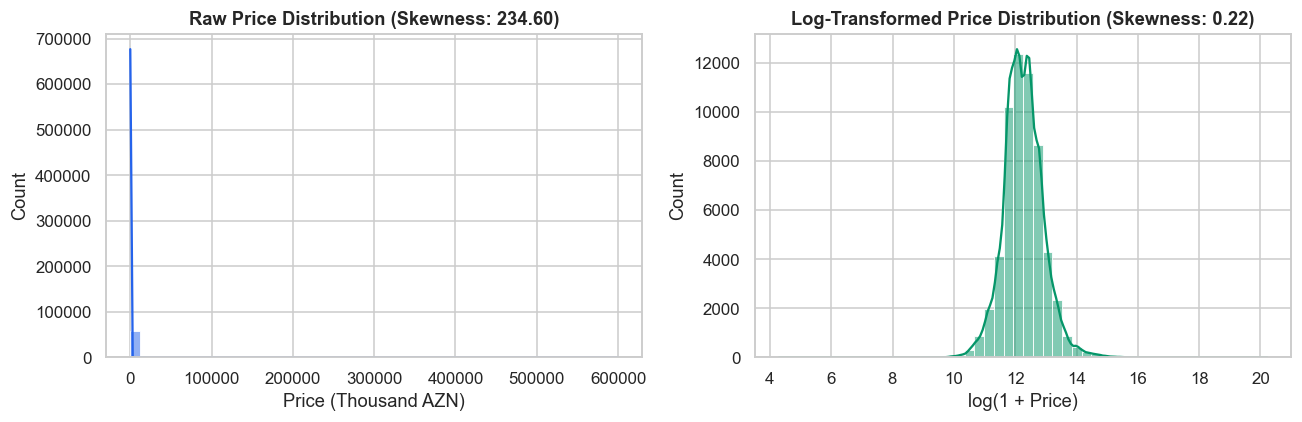

In [14]:
# Distribution of Raw Price vs. Log-Transformed Price
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['price'] / 1000, bins=50, kde=True, ax=ax1, color='#2563EB')
ax1.set_title(f'Raw Price Distribution (Skewness: {raw_skew:.2f})', fontweight='bold')
ax1.set_xlabel('Price (Thousand AZN)')

sns.histplot(log_price_series, bins=50, kde=True, ax=ax2, color='#059669')
ax2.set_title(f'Log-Transformed Price Distribution (Skewness: {log_skew:.2f})', fontweight='bold')
ax2.set_xlabel('log(1 + Price)')
plt.tight_layout()
plt.show()

## 03. Feature Engineering & Column Separation

We extract numerical properties from text attributes, calculate spatial distance to Baku city center, and separate numerical and categorical columns.

In [15]:
# Parse numeric area (m²) and floor numbers
df['area'] = clean_area(df['Sahə'])
floor_df = parse_floors(df['Mərtəbə'])
df['current_floor'] = floor_df['current_floor']
df['total_floors'] = floor_df['total_floors']

df[['Sahə', 'area', 'Mərtəbə', 'current_floor', 'total_floors']].head()

,Sahə,area,Mərtəbə,current_floor,total_floors
2318,200 m²,200.0,NaN,NaN,NaN
2323,130 m²,130.0,9 / 10,9.0,10.0
2325,160 m²,160.0,NaN,NaN,NaN
2327,95 m²,95.0,3 / 16,3.0,16.0
2328,85 m²,85.0,16 / 16,16.0,16.0


In [16]:
# Spatial bounding box and realistic market boundaries
# Valid Baku & Absheron bounds: Lat [40.10, 40.65], Lng [49.60, 50.40]
geo_mask = (df['lat'] >= 40.10) & (df['lat'] <= 40.65) & (df['lng'] >= 49.60) & (df['lng'] <= 50.40)
unit_p = df['price'] / df['area']
valid_mask = geo_mask & (
    (df['price'] >= 25000) & (df['price'] <= 2000000) &
    (df['area'] >= 15) & (df['area'] <= 600) &
    (unit_p >= 300) & (unit_p <= 10000)
)
df_clean = df[valid_mask].copy()
df_clean['unit_calc'] = df_clean['price'] / df_clean['area']
df_clean['log_price'] = np.log1p(df_clean['price'])
print(f"Cleaned dataset: {df_clean.shape[0]:,} listings retained ({df_clean.shape[0]/df.shape[0]*100:.2f}%).")

Cleaned dataset: 57,707 listings retained (98.73%).


In [17]:
# Distance to Baku city center (Fountain Square: 40.3725° N, 49.8360° E)
df_clean['dist_center_km'] = haversine_distance(df_clean['lat'], df_clean['lng'])
print(f"Median distance to city center: {df_clean['dist_center_km'].median():.2f} km")

Median distance to city center: 4.87 km


In [18]:
# Structural ratios and floor indicators
rooms = df_clean['Otaq sayı'].fillna(df_clean['Otaq sayı'].median())
df_clean['area_per_room'] = df_clean['area'] / np.maximum(rooms, 1)
df_clean['floor_ratio'] = np.where(df_clean['total_floors'] > 0, df_clean['current_floor'] / df_clean['total_floors'], 0.5)
df_clean['is_first_floor'] = (df_clean['current_floor'] == 1).astype(int)
df_clean['is_last_floor'] = ((df_clean['current_floor'] == df_clean['total_floors']) & (df_clean['total_floors'] > 1)).astype(int)

In [19]:
# Legal and documentation flags (Title Deed / Kupcha, Repair, Mortgage eligibility)
df_clean['has_bill_of_sale'] = ((df_clean['bill_of_sale'] == 'Çıxarış var') | (df_clean['Çıxarış'] == 'var')).astype(int)
df_clean['has_repair'] = ((df_clean['repair'] == 'Təmirli') | (df_clean['Təmir'] == 'var')).astype(int)
df_clean['has_mortgage'] = ((df_clean['mortgage'] == 'İpoteka var') | (df_clean['İpoteka'] == 'var')).astype(int)
print(f"Title deed (Kupcha) presence: {df_clean['has_bill_of_sale'].mean()*100:.1f}% | Repair presence: {df_clean['has_repair'].mean()*100:.1f}%")

Title deed (Kupcha) presence: 77.9% | Repair presence: 85.6%


In [20]:
# Clean amenity keyword signals with word boundaries avoiding 'kv.m.' false positives
amenities = extract_amenities(df_clean['description'])
df_clean['has_metro'] = amenities['has_metro']
df_clean['has_sea_view'] = amenities['has_sea_view']
df_clean['has_gas_lift'] = amenities['has_gas_lift']

print(f"Amenity presence - Metro: {df_clean['has_metro'].mean()*100:.1f}%, Sea View: {df_clean['has_sea_view'].mean()*100:.1f}%, Gas+Lift: {df_clean['has_gas_lift'].mean()*100:.1f}%")

Amenity presence - Metro: 15.5%, Sea View: 3.2%, Gas+Lift: 7.5%


In [21]:
# Separate numeric and categorical predictor columns
numeric_features = [
    'area', 'Otaq sayı', 'current_floor', 'total_floors',
    'floor_ratio', 'is_first_floor', 'is_last_floor',
    'lat', 'lng', 'has_repair', 'has_bill_of_sale', 'has_mortgage',
    'dist_center_km', 'area_per_room', 'has_sea_view', 'has_metro', 'has_gas_lift'
]
categorical_features = ['Kateqoriya', 'location']

print(f"Numerical Features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical Features ({len(categorical_features)}): {categorical_features}")

Numerical Features (17): ['area', 'Otaq sayı', 'current_floor', 'total_floors', 'floor_ratio', 'is_first_floor', 'is_last_floor', 'lat', 'lng', 'has_repair', 'has_bill_of_sale', 'has_mortgage', 'dist_center_km', 'area_per_room', 'has_sea_view', 'has_metro', 'has_gas_lift']
Categorical Features (2): ['Kateqoriya', 'location']


## 04. Missing Value Analysis & Cleaning Decisions

We inspect missingness across all features and document features dropped due to leakage or high sparsity.

In [22]:
# Check missing value percentages across all features
missing_pct = (df_clean[numeric_features + categorical_features].isnull().sum() / len(df_clean)) * 100
missing_df = pd.DataFrame({'Missing (%)': missing_pct[missing_pct > 0].sort_values(ascending=False)})
print("Features with Missing Values:")
display(missing_df)

Features with Missing Values:


,Missing (%)
current_floor,15.651481
total_floors,15.651481
Otaq sayı,0.315386


**Visual Insight:** Displays the percentage of missing values across selected modeling features (predominantly 0%, with minor gaps imputed via median).

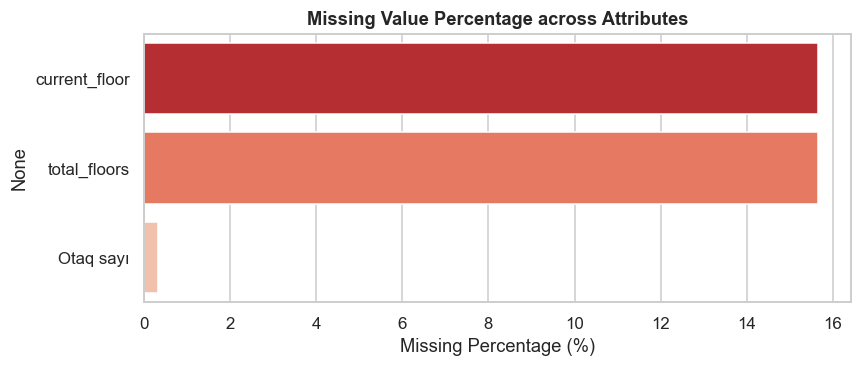

In [23]:
# Missing Value Percentage across Attributes
plt.figure(figsize=(8, 3.5))
if len(missing_df) > 0:
    sns.barplot(x=missing_df['Missing (%)'], y=missing_df.index, hue=missing_df.index, legend=False, palette='Reds_r')
    plt.title('Missing Value Percentage across Attributes', fontweight='bold')
    plt.xlabel('Missing Percentage (%)')
else:
    plt.text(0.5, 0.5, 'Zero Missing Values in Selected Predictors', ha='center', va='center')
plt.tight_layout()
plt.show()

### Feature Dropping Justification Table:
| Feature Name | Reason for Exclusion / Dropping |
| :--- | :--- |
| `views_count`, `vip`, `featured` | Target leakage: Portal engagement metrics generated after listing creation |
| `id_x`, `id_y`, `estate_id` | Arbitrary database identifiers with zero predictive power |
| `description` (raw string) | High-cardinality unstructured text (distilled into binary amenity signals) |
| `datetime_scrape_x`, `datetime_scrape_y` | Scrape metadata with temporal bias; dedup performed on estate_rel_url_x |

## 05. Exploratory Data Analysis (EDA)

We explore spatial distributions, correlations, property categories, distance decay, and title deed impacts.

**Visual Insight:** Geospatial map of property listings across the Absheron Peninsula colored by unit price (AZN/m²), highlighting the prime central downtown core (red star) and coastal villa clusters.

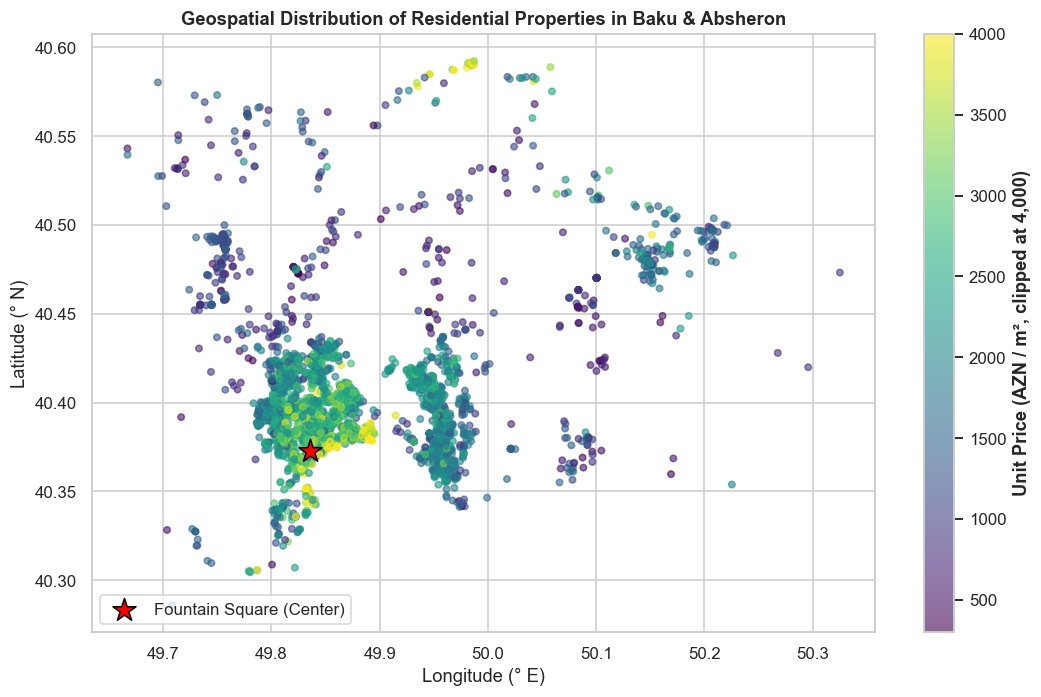

In [24]:
# Geospatial Property Distribution & Pricing Map
plt.figure(figsize=(10, 6.5))
sample_map = df_clean.sample(min(4000, len(df_clean)), random_state=42)
scatter = plt.scatter(
    sample_map['lng'], sample_map['lat'],
    c=np.clip(sample_map['unit_calc'], 300, 4000),
    cmap='viridis', alpha=0.6, s=18
)
cbar = plt.colorbar(scatter)
cbar.set_label('Unit Price (AZN / m², clipped at 4,000)', fontweight='bold')
plt.scatter([49.8360], [40.3725], color='red', marker='*', s=250, label='Fountain Square (Center)', edgecolors='black', zorder=5)
plt.title('Geospatial Distribution of Residential Properties in Baku & Absheron', fontweight='bold')
plt.xlabel('Longitude (° E)')
plt.ylabel('Latitude (° N)')
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

**Visual Insight:** Displays Pearson correlation among core numerical features (strong positive correlation for area and rooms with price, negative with distance to center).

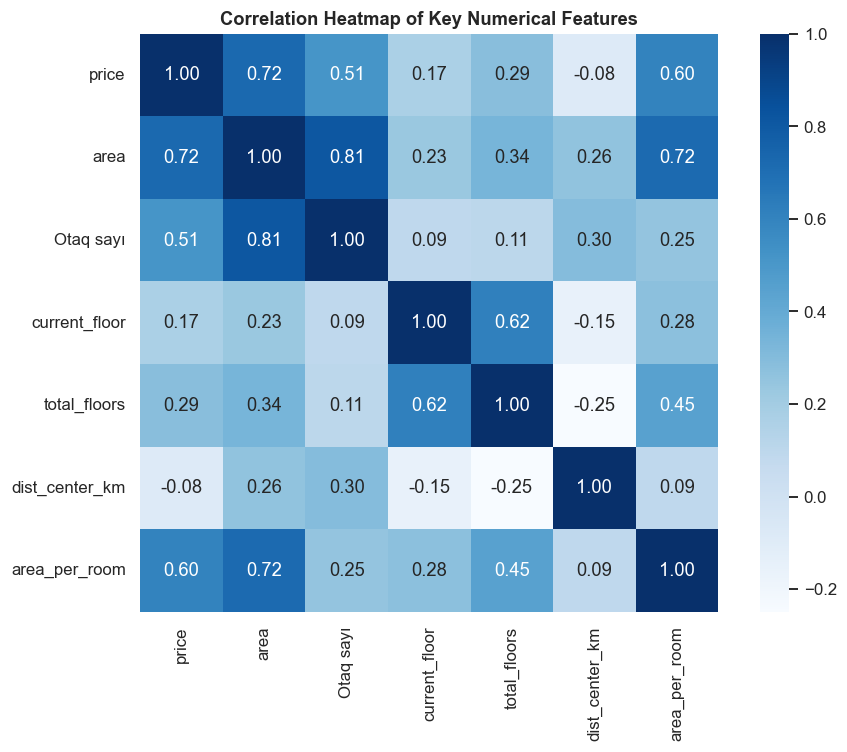

In [25]:
# Correlation Heatmap of Numerical Features
corr_features = ['price', 'area', 'Otaq sayı', 'current_floor', 'total_floors', 'dist_center_km', 'area_per_room']
plt.figure(figsize=(9, 7))
sns.heatmap(df_clean[corr_features].corr(), annot=True, fmt='.2f', cmap='Blues', cbar=True, square=True)
plt.title('Correlation Heatmap of Key Numerical Features', fontweight='bold')
plt.tight_layout()
plt.show()

**Visual Insight:** Visualizes pairwise relationships between price, area, rooms, and center distance stratified across residential property categories.

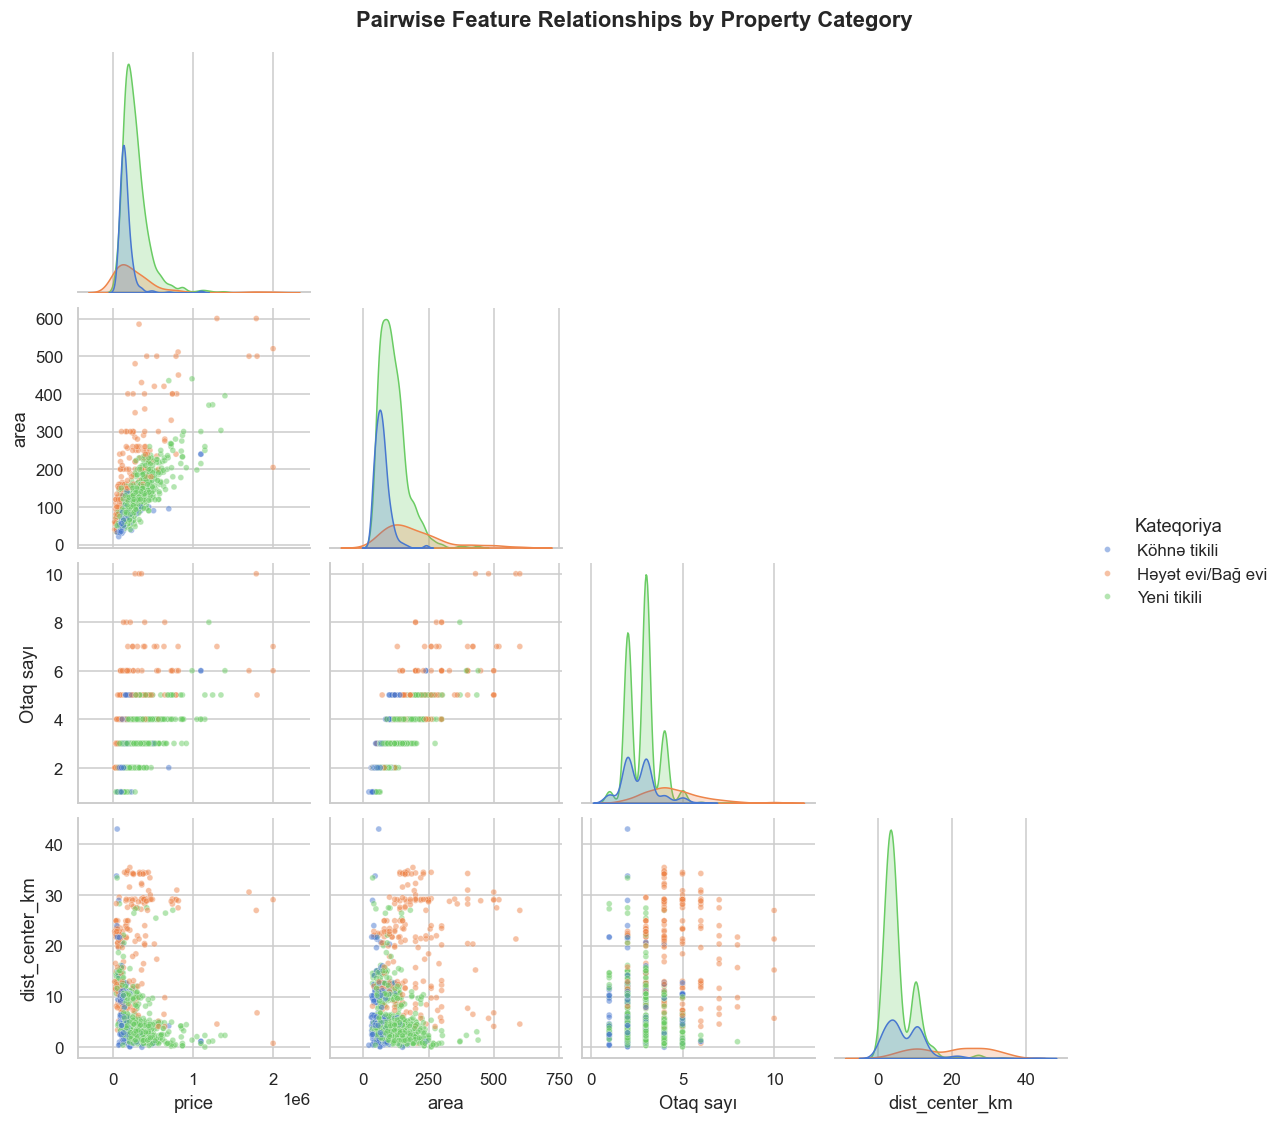

In [26]:
# Pairplot of Key Numerical Predictors
sample_pair = df_clean.sample(min(1500, len(df_clean)), random_state=42)
sns.pairplot(
    sample_pair[['price', 'area', 'Otaq sayı', 'dist_center_km', 'Kateqoriya']],
    hue='Kateqoriya',
    corner=True,
    plot_kws={'alpha': 0.5, 's': 15}
)
plt.suptitle('Pairwise Feature Relationships by Property Category', y=1.02, fontweight='bold')
plt.show()

**Visual Insight:** Displays the empirical distribution of square meter prices across Baku (median around ~2,200 AZN/m² with right-tail density).

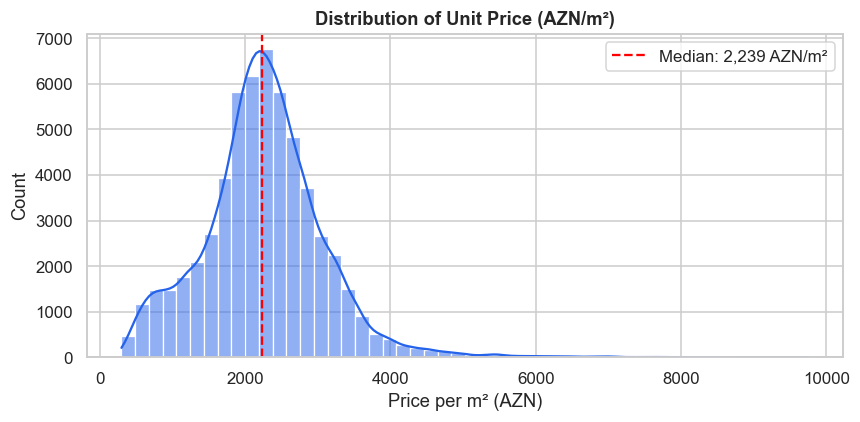

In [27]:
# Distribution of Unit Price (AZN/m²)
plt.figure(figsize=(8, 4))
sns.histplot(df_clean['unit_calc'], bins=50, kde=True, color='#2563EB')
plt.axvline(df_clean['unit_calc'].median(), color='red', linestyle='--', label=f"Median: {df_clean['unit_calc'].median():,.0f} AZN/m²")
plt.title('Distribution of Unit Price (AZN/m²)', fontweight='bold')
plt.xlabel('Price per m² (AZN)')
plt.legend()
plt.tight_layout()
plt.show()

**Visual Insight:** Shows the overall area distribution of residential properties (the bulk of listings cluster within 60–140 m²).

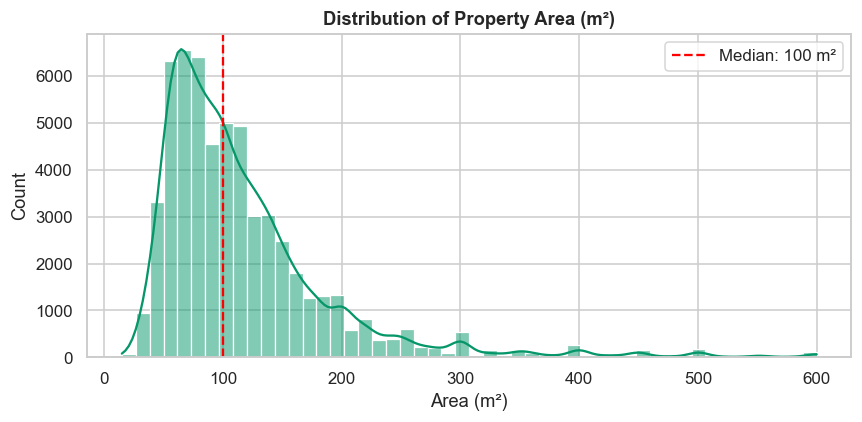

In [28]:
# Distribution of Area (m²)
plt.figure(figsize=(8, 4))
sns.histplot(df_clean['area'], bins=50, kde=True, color='#059669')
plt.axvline(df_clean['area'].median(), color='red', linestyle='--', label=f"Median: {df_clean['area'].median():,.0f} m²")
plt.title('Distribution of Property Area (m²)', fontweight='bold')
plt.xlabel('Area (m²)')
plt.legend()
plt.tight_layout()
plt.show()

**Visual Insight:** Highlights non-linear hedonic price decay as geodesic distance increases from Fountain Square (city center).

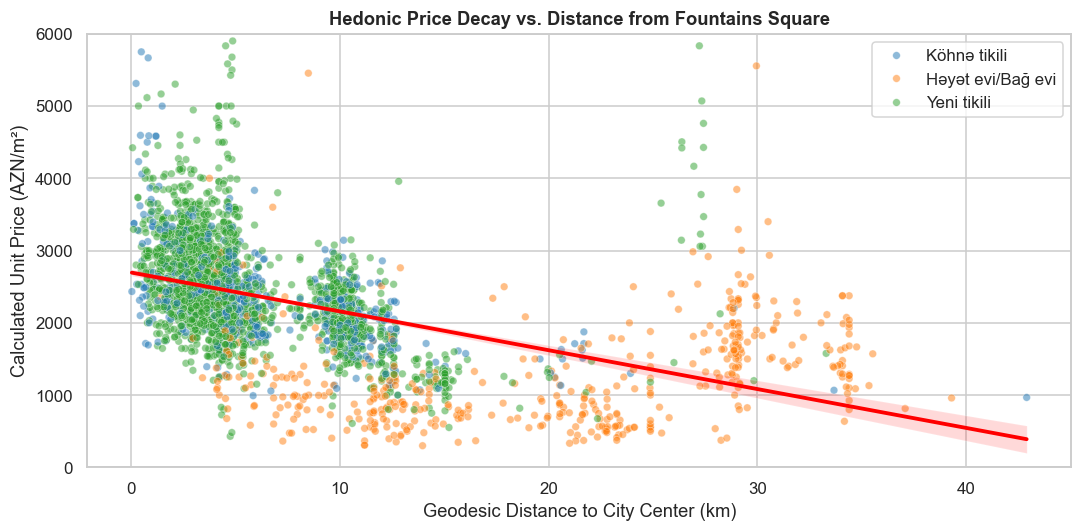

In [29]:
# Hedonic Price Decay vs. Distance from Fountains Square
plt.figure(figsize=(10, 5))
sample_eda = df_clean.sample(min(3000, len(df_clean)), random_state=42)
sns.scatterplot(
    data=sample_eda, x='dist_center_km', y='unit_calc',
    hue='Kateqoriya', alpha=0.5, s=25, palette='tab10'
)
sns.regplot(
    data=sample_eda, x='dist_center_km', y='unit_calc',
    scatter=False, color='red', line_kws={'linewidth': 2.5, 'label': 'Hedonic Decay Trend'}
)
plt.title('Hedonic Price Decay vs. Distance from Fountains Square', fontweight='bold')
plt.xlabel('Geodesic Distance to City Center (km)')
plt.ylabel('Calculated Unit Price (AZN/m²)')
plt.ylim(0, 6000)
plt.legend()
plt.tight_layout()
plt.show()

**Visual Insight:** Compares the listing price distribution and median values across the three major residential categories.

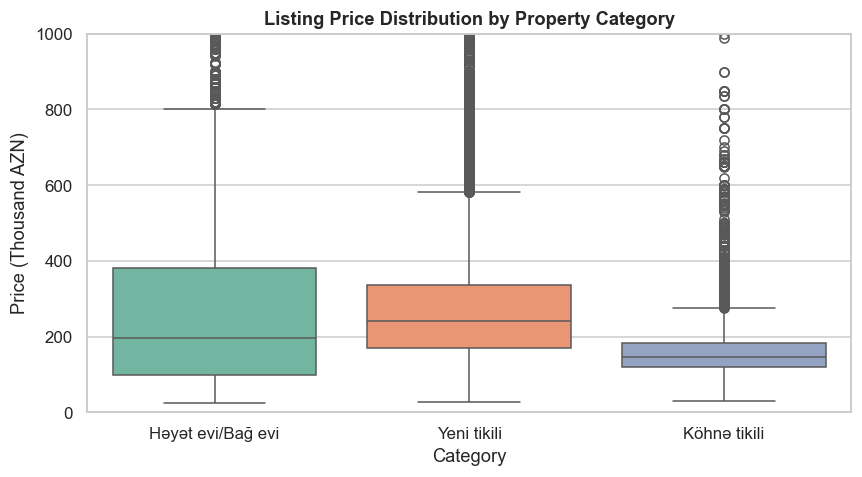

In [30]:
# Price Distribution by Property Category
plt.figure(figsize=(8, 4.5))
sns.boxplot(data=df_clean, x='Kateqoriya', y=df_clean['price']/1000, hue='Kateqoriya', legend=False, palette='Set2')
plt.title('Listing Price Distribution by Property Category', fontweight='bold')
plt.xlabel('Category')
plt.ylabel('Price (Thousand AZN)')
plt.ylim(0, 1000)
plt.tight_layout()
plt.show()

**Visual Insight:** Demonstrates the step-wise market price progression as room count scales from 1 to 6 rooms.

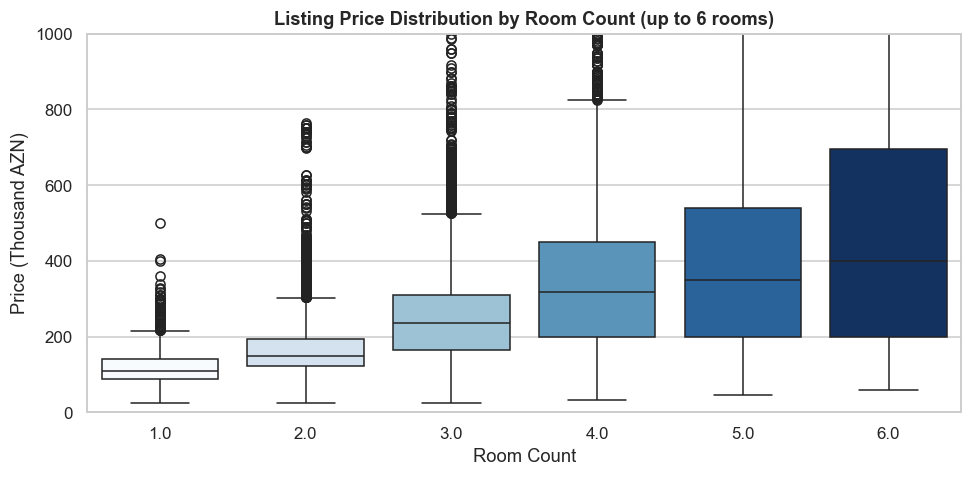

In [31]:
# Price Distribution by Room Count
plt.figure(figsize=(9, 4.5))
sns.boxplot(data=df_clean[df_clean['Otaq sayı'] <= 6], x='Otaq sayı', y=df_clean['price']/1000, hue='Otaq sayı', legend=False, palette='Blues')
plt.title('Listing Price Distribution by Room Count (up to 6 rooms)', fontweight='bold')
plt.xlabel('Room Count')
plt.ylabel('Price (Thousand AZN)')
plt.ylim(0, 1000)
plt.tight_layout()
plt.show()

**Visual Insight:** Illustrates median unit price across radial distance bands from the center (dropping to 950 AZN at 15–25 km, rebounding to 1,656 AZN at 25+ km).

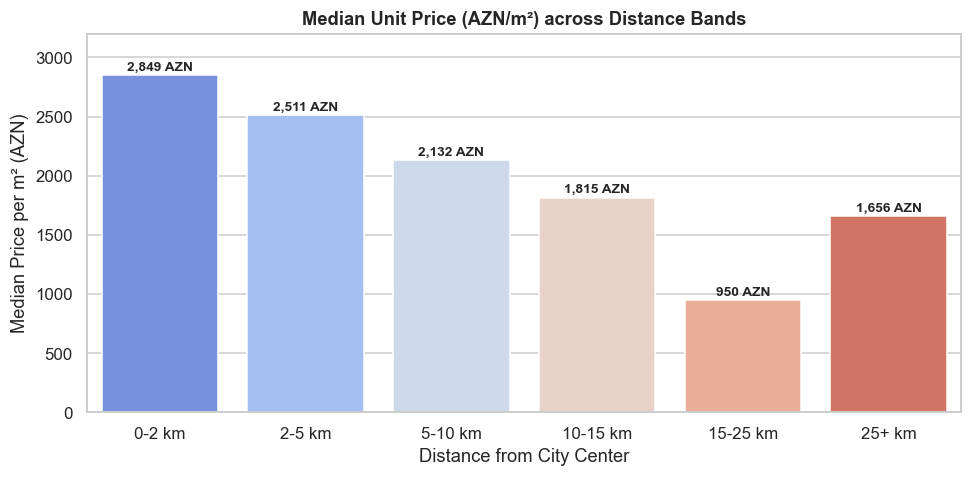

In [32]:
# Median Unit Price across Distance Bands
dist_bins = [0, 2, 5, 10, 15, 25, 100]
dist_labels = ['0-2 km', '2-5 km', '5-10 km', '10-15 km', '15-25 km', '25+ km']
df_clean['dist_band'] = pd.cut(df_clean['dist_center_km'], bins=dist_bins, labels=dist_labels)

dist_summary = df_clean.groupby('dist_band', observed=True)['unit_calc'].agg(['median', 'count']).reset_index()

plt.figure(figsize=(9, 4.5))
sns.barplot(data=dist_summary, x='dist_band', y='median', hue='dist_band', legend=False, palette='coolwarm')
for i, row in dist_summary.iterrows():
    plt.text(i, row['median'] + 40, f"{row['median']:,.0f} AZN", ha='center', fontweight='bold', fontsize=9)
plt.title('Median Unit Price (AZN/m²) across Distance Bands', fontweight='bold')
plt.xlabel('Distance from City Center')
plt.ylabel('Median Price per m² (AZN)')
plt.ylim(0, 3200)
plt.tight_layout()
plt.show()

### Distance Band Economics:
* **0–2 km (Baku Downtown):** Highest median price (**2,849 AZN/m²**) due to prime commercial, diplomatic, and historic value.
* **15–25 km (Absheron Periphery):** Minimum median price (**950 AZN/m²**), representing suburban settlements (Masazir, Hovsan).
* **25+ km (Coastal Villa Belt):** Price rebound to **1,656 AZN/m²** driven by premium coastal summer villas in Bilgah, Mardakan, and Shuvalan.

**Visual Insight:** Compares listing prices based on title deed (Kupcha) ownership via boxplots.

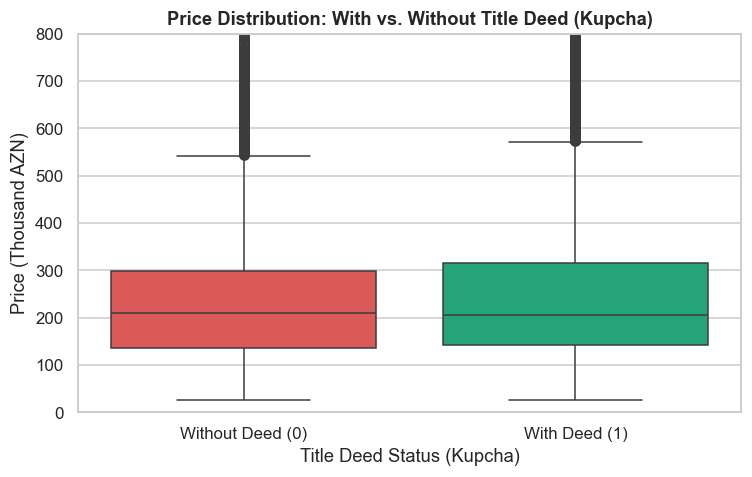

In [33]:
# Price Distribution: With vs. Without Title Deed (Kupcha)
plt.figure(figsize=(7, 4.5))
sns.boxplot(data=df_clean, x='has_bill_of_sale', y=df_clean['price']/1000, hue='has_bill_of_sale', legend=False, palette=['#EF4444', '#10B981'])
plt.xticks([0, 1], ['Without Deed (0)', 'With Deed (1)'])
plt.title('Price Distribution: With vs. Without Title Deed (Kupcha)', fontweight='bold')
plt.xlabel('Title Deed Status (Kupcha)')
plt.ylabel('Price (Thousand AZN)')
plt.ylim(0, 800)
plt.tight_layout()
plt.show()

**Visual Insight:** Compares empirical price per m² with vs. without Kupcha across property types (showing a dramatic +80.3% gap for detached houses/villas vs. minimal difference for urban apartments).

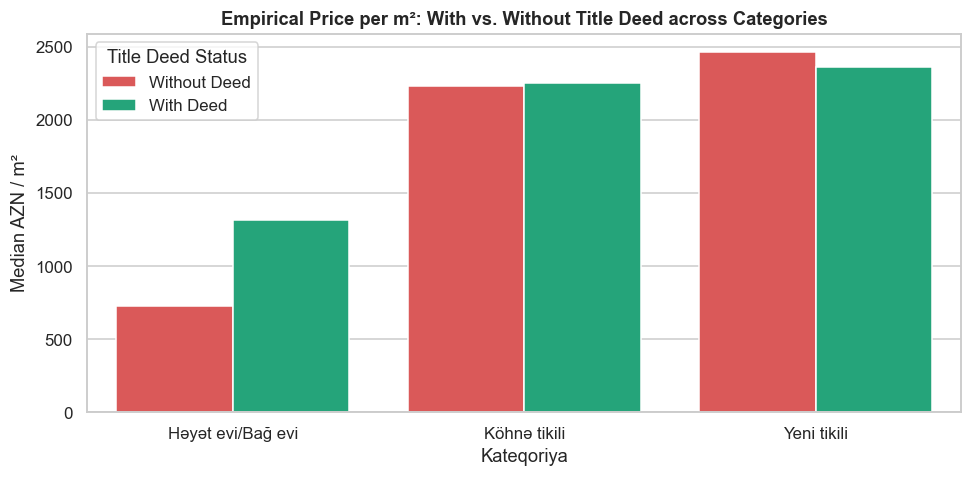

,Without Deed,With Deed,Diff (%)
Kateqoriya,,,
Həyət evi/Bağ evi,727.9,1312.5,80.3
Köhnə tikili,2235.3,2250.0,0.7
Yeni tikili,2466.7,2364.4,-4.1


In [34]:
# Empirical Price per m²: With vs. Without Title Deed across Categories
kupca_comp = df_clean.groupby(['Kateqoriya', 'has_bill_of_sale'], observed=True)['unit_calc'].median().unstack()
kupca_comp.columns = ['Without Deed', 'With Deed']
kupca_comp['Diff (%)'] = ((kupca_comp['With Deed'] - kupca_comp['Without Deed']) / kupca_comp['Without Deed']) * 100

plt.figure(figsize=(9, 4.5))
kupca_plot_df = kupca_comp[['Without Deed', 'With Deed']].reset_index().melt(id_vars='Kateqoriya', var_name='Title Deed Status', value_name='Median AZN/m²')
sns.barplot(data=kupca_plot_df, x='Kateqoriya', y='Median AZN/m²', hue='Title Deed Status', palette=['#EF4444', '#10B981'])
plt.title('Empirical Price per m²: With vs. Without Title Deed across Categories', fontweight='bold')
plt.ylabel('Median AZN / m²')
plt.tight_layout()
plt.show()

display(kupca_comp.round(1))

**Visual Insight:** Depicts the distribution of normalized building floor position (`floor_ratio`) across new vs. secondary construction.

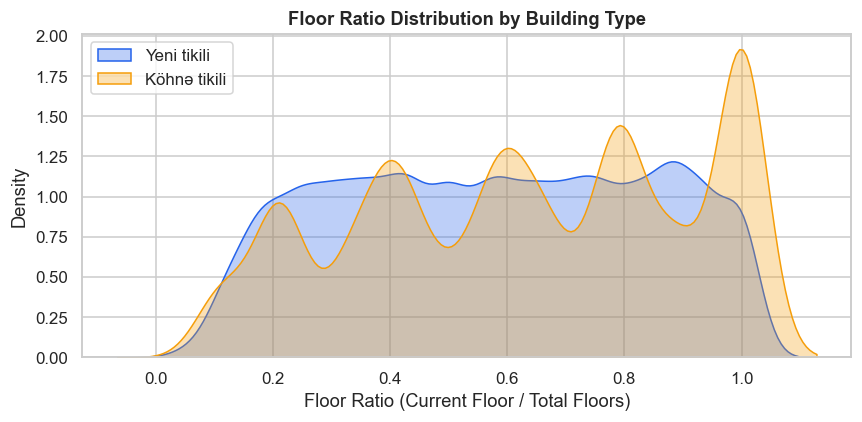

In [35]:
# Floor Ratio Distribution by Building Type
plt.figure(figsize=(8, 4))
sns.kdeplot(data=df_clean[df_clean['Kateqoriya'] == 'Yeni tikili'], x='floor_ratio', label='Yeni tikili', fill=True, alpha=0.3, color='#2563EB')
sns.kdeplot(data=df_clean[df_clean['Kateqoriya'] == 'Köhnə tikili'], x='floor_ratio', label='Köhnə tikili', fill=True, alpha=0.3, color='#F59E0B')
plt.title('Floor Ratio Distribution by Building Type', fontweight='bold')
plt.xlabel('Floor Ratio (Current Floor / Total Floors)')
plt.legend()
plt.tight_layout()
plt.show()

**Visual Insight:** Highlights the unit price differential between ground floor, middle floors, and top floors in apartment buildings.

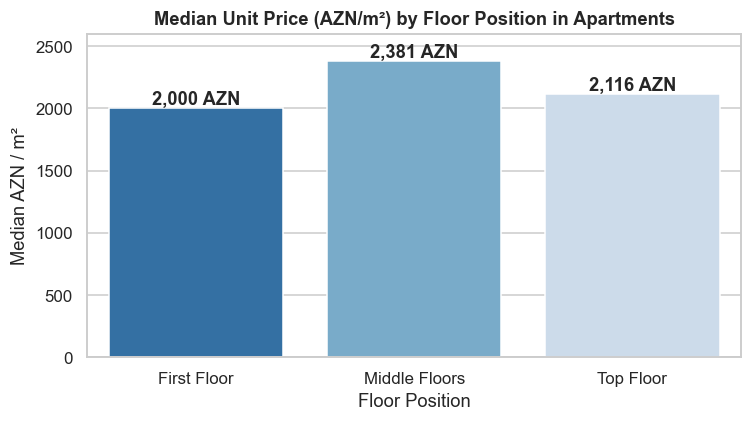

In [36]:
# Price Comparison: Ground Floor vs. Middle Floors vs. Top Floor
df_clean['floor_position'] = 'Middle Floors'
df_clean.loc[df_clean['is_first_floor'] == 1, 'floor_position'] = 'First Floor'
df_clean.loc[df_clean['is_last_floor'] == 1, 'floor_position'] = 'Top Floor'

floor_pos_summary = df_clean[df_clean['Kateqoriya'].isin(['Yeni tikili', 'Köhnə tikili'])].groupby('floor_position', observed=True)['unit_calc'].median().reset_index()

plt.figure(figsize=(7, 4))
sns.barplot(data=floor_pos_summary, x='floor_position', y='unit_calc', hue='floor_position', legend=False, palette='Blues_r')
for i, row in floor_pos_summary.iterrows():
    plt.text(i, row['unit_calc'] + 30, f"{row['unit_calc']:,.0f} AZN", ha='center', fontweight='bold')
plt.title('Median Unit Price (AZN/m²) by Floor Position in Apartments', fontweight='bold')
plt.xlabel('Floor Position')
plt.ylabel('Median AZN / m²')
plt.ylim(0, 2600)
plt.tight_layout()
plt.show()

## 06. Outlier Detection & Handling

We inspect physical and economic anomalies using IQR and bounded domain filtering.

In [37]:
# Domain economic and geographic boundaries summary
print("Outlier Mitigation Protocol Summary:")
print(f"• Minimum Listing Price:    25,000 AZN")
print(f"• Maximum Listing Price:    2,000,000 AZN")
print(f"• Area Boundaries:          15 m² to 600 m²")
print(f"• Unit Price Range:         300 AZN/m² to 10,000 AZN/m²")
print(f"• Latitude / Longitude:     Baku Metropolitan Bounding Box [40.10 - 40.65° N, 49.60 - 50.40° E]")

Outlier Mitigation Protocol Summary:
• Minimum Listing Price:    25,000 AZN
• Maximum Listing Price:    2,000,000 AZN
• Area Boundaries:          15 m² to 600 m²
• Unit Price Range:         300 AZN/m² to 10,000 AZN/m²
• Latitude / Longitude:     Baku Metropolitan Bounding Box [40.10 - 40.65° N, 49.60 - 50.40° E]


## 07. Train / Validation / Test Split (Strict Leakage Prevention)

We apply a strict **70% Train / 15% Validation / 15% Holdout Test** split. Transformers and target encoders are fitted solely on the training partition.

In [38]:
# Strict 70 / 15 / 15 Split Protocol
from sklearn.model_selection import train_test_split

feature_cols = numeric_features + ['Kateqoriya', 'location']
X = df_clean[feature_cols].copy()
y = df_clean['price'].copy()

X_train_raw, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)

y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)
y_test_log = np.log1p(y_test)

print(f"Partition Sizes -> Train: {X_train_raw.shape[0]:,} | Val: {X_val_raw.shape[0]:,} | Test: {X_test_raw.shape[0]:,}")

Partition Sizes -> Train: 40,394 | Val: 8,656 | Test: 8,657


In [39]:
# Mine Top 15 locations strictly from Train set to prevent leakage
top_train_locations = X_train_raw['location'].value_counts().head(15).index.tolist()

def bin_locations(df_split, allowed_locs):
    df_out = df_split.copy()
    df_out['location_binned'] = df_out['location'].apply(lambda x: x if x in allowed_locs else 'Other')
    return df_out.drop(columns=['location'])

X_train_binned = bin_locations(X_train_raw, top_train_locations)
X_val_binned = bin_locations(X_val_raw, top_train_locations)
X_test_binned = bin_locations(X_test_raw, top_train_locations)

print(f"Locations mapped to {len(top_train_locations)} prominent classes + 'Other'.")

Locations mapped to 15 prominent classes + 'Other'.


In [40]:
# Build Scikit-Learn ColumnTransformer pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Other')),
    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, numeric_features),
    ('cat', cat_pipeline, ['Kateqoriya', 'location_binned'])
])

X_train_proc = preprocessor.fit_transform(X_train_binned)
X_val_proc = preprocessor.transform(X_val_binned)
X_test_proc = preprocessor.transform(X_test_binned)

print(f"Preprocessed feature dimensions: {X_train_proc.shape[1]}")

Preprocessed feature dimensions: 36


## 08. Model Training & Validation Benchmarking

We evaluate Ridge Regression, Random Forest, and XGBoost across tree depths on the Validation set.

In [41]:
# Define standard AVM evaluation metrics function
from sklearn.metrics import r2_score, mean_absolute_error

def eval_avm_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    ape = np.abs((y_true - y_pred) / y_true) * 100
    medape = np.median(ape)
    mape = np.mean(ape)
    ppe10 = np.mean(ape <= 10.0) * 100
    ppe20 = np.mean(ape <= 20.0) * 100
    return {'R2': r2, 'MAE': mae, 'MedAPE': medape, 'MAPE': mape, 'PPE10': ppe10, 'PPE20': ppe20}

In [42]:
# Train baseline Ridge Regression model
from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=10.0)
ridge_model.fit(X_train_proc, y_train_log)

val_pred_ridge = np.expm1(ridge_model.predict(X_val_proc))
val_ridge_metrics = eval_avm_metrics(y_val, val_pred_ridge)
print(f"Validation Ridge -> R²: {val_ridge_metrics['R2']:.4f} | MAE: {val_ridge_metrics['MAE']:,.2f} AZN | MedAPE: {val_ridge_metrics['MedAPE']:.2f}%")

Validation Ridge -> R²: 0.5043 | MAE: 58,260.45 AZN | MedAPE: 13.84%


In [43]:
# Train Random Forest Regressor benchmark
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=150, max_depth=16, min_samples_split=6,
    min_samples_leaf=2, max_features=0.8, random_state=42, n_jobs=-1
)
rf_model.fit(X_train_proc, y_train_log)

val_pred_rf = np.expm1(rf_model.predict(X_val_proc))
val_rf_metrics = eval_avm_metrics(y_val, val_pred_rf)
print(f"Validation Random Forest -> R²: {val_rf_metrics['R2']:.4f} | MAE: {val_rf_metrics['MAE']:,.2f} AZN | MedAPE: {val_rf_metrics['MedAPE']:.2f}%")

Validation Random Forest -> R²: 0.8359 | MAE: 33,947.72 AZN | MedAPE: 7.50%


In [44]:
# Systematic XGBoost Depth Tuning on Validation Set
from xgboost import XGBRegressor

tuning_results = []
depth_candidates = [5, 6, 7, 8, 9, 10, 11]

for d in depth_candidates:
    m = XGBRegressor(
        max_depth=d, learning_rate=0.06, n_estimators=300,
        subsample=0.85, colsample_bytree=0.80, random_state=42, n_jobs=-1
    )
    m.fit(X_train_proc, y_train_log)
    
    val_pred = np.expm1(m.predict(X_val_proc))
    tr_pred = np.expm1(m.predict(X_train_proc))
    
    val_met = eval_avm_metrics(y_val, val_pred)
    tr_r2 = r2_score(y_train, tr_pred)
    
    tuning_results.append({
        'Depth': d,
        'Train R²': round(tr_r2, 4),
        'Val R²': round(val_met['R2'], 4),
        'Gap': round(tr_r2 - val_met['R2'], 4),
        'Val MedAPE (%)': round(val_met['MedAPE'], 2),
        'Val PPE10 (%)': round(val_met['PPE10'], 2)
    })

In [45]:
# Display hyperparameter exploration table
tuning_df = pd.DataFrame(tuning_results)
display(tuning_df)

,Depth,Train R²,Val R²,Gap,Val MedAPE (%),Val PPE10 (%)
0,5,0.8521,0.8161,0.0360,9.69,51.22
1,6,0.8820,0.8274,0.0546,9.02,54.10
2,7,0.9084,0.8339,0.0745,8.66,55.78
3,8,0.9339,0.8387,0.0952,8.16,57.95
4,9,0.9546,0.8426,0.1120,7.61,60.36
5,10,0.9703,0.8484,0.1219,7.20,61.90
6,11,0.9808,0.8474,0.1334,6.93,63.49


**Visual Insight:** Tracks validation R² and MedAPE curves across XGBoost tree depths, illustrating where peak performance is achieved.

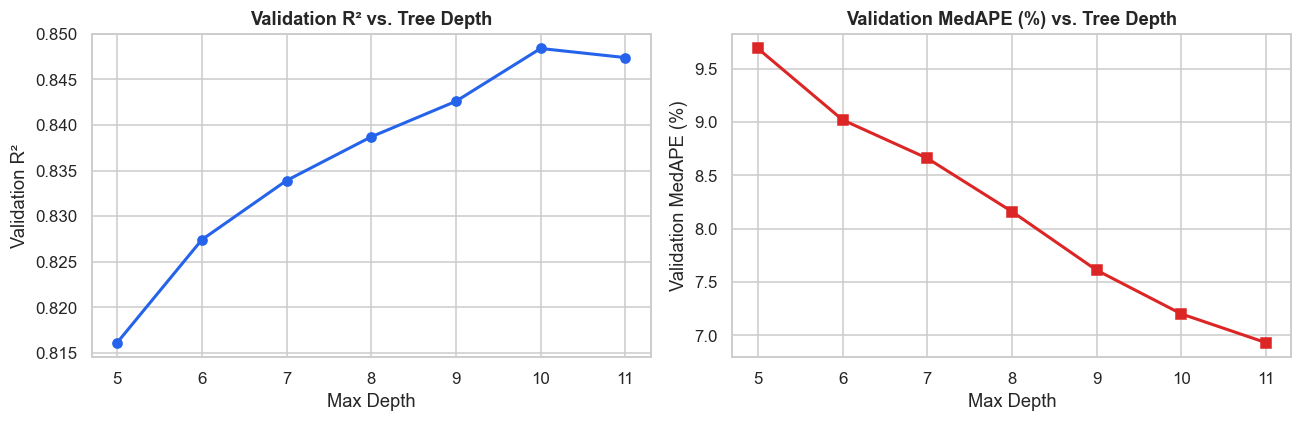

In [46]:
# Validation Tuning Curves across Tree Depths
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(tuning_df['Depth'], tuning_df['Val R²'], marker='o', color='#2563EB', lw=2)
ax1.set_title('Validation R² vs. Tree Depth', fontweight='bold')
ax1.set_xlabel('Max Depth')
ax1.set_ylabel('Validation R²')

ax2.plot(tuning_df['Depth'], tuning_df['Val MedAPE (%)'], marker='s', color='#DC2626', lw=2)
ax2.set_title('Validation MedAPE (%) vs. Tree Depth', fontweight='bold')
ax2.set_xlabel('Max Depth')
ax2.set_ylabel('Validation MedAPE (%)')
plt.tight_layout()
plt.show()

### Model Selection Decision Rule:
* **Selection Rule:** Select the deepest tree architecture that maintains a generalization gap strictly under 0.1200 ($\Delta R^2 < 0.1200$).
* **Depth 9** satisfies this constraint with a generalization gap of **0.1120**, achieving strong validation performance (Val $R^2 = 0.8426$, MedAPE = 7.61%, PPE10 = 60.36%).
* While Depth 10 increases Val $R^2$ marginally (+0.0058) and improves MedAPE by 0.41%, its generalization gap widens to **0.1219** (> 0.1200) and Train $R^2$ exceeds 0.97, indicating early signs of memorization.
* Therefore, **Depth 9 is selected as our gap-constrained Champion model**.

In [47]:
# Fit final Champion XGBoost model (max_depth=9)
champion_xgb = XGBRegressor(
    max_depth=9, learning_rate=0.06, n_estimators=300,
    subsample=0.85, colsample_bytree=0.80, random_state=42, n_jobs=-1
)
champion_xgb.fit(X_train_proc, y_train_log)
print("Champion XGBoost model fitted on Train set.")

Champion XGBoost model fitted on Train set.


## 09. Holdout Test Set Final Evaluation & Generalization Gap Analysis

We evaluate all models on the strictly unseen holdout test set for unbiased final reporting, followed by a comprehensive Train vs. Validation vs. Test gap comparison.

In [48]:
# Evaluate models on Holdout Test Set
y_test_pred_xgb = np.expm1(champion_xgb.predict(X_test_proc))
y_test_pred_rf = np.expm1(rf_model.predict(X_test_proc))
y_test_pred_ridge = np.expm1(ridge_model.predict(X_test_proc))

test_xgb_metrics = eval_avm_metrics(y_test, y_test_pred_xgb)
test_rf_metrics = eval_avm_metrics(y_test, y_test_pred_rf)
test_ridge_metrics = eval_avm_metrics(y_test, y_test_pred_ridge)

In [49]:
# Construct Holdout Test Comparison Table
test_results_df = pd.DataFrame([
    {
        'Model': 'Tuned XGBoost (max_depth=9)',
        'Test R²': test_xgb_metrics['R2'],
        'Test MAE (AZN)': test_xgb_metrics['MAE'],
        'MedAPE (%)': test_xgb_metrics['MedAPE'],
        'PPE10 (%)': test_xgb_metrics['PPE10'],
        'PPE20 (%)': test_xgb_metrics['PPE20']
    },
    {
        'Model': 'Random Forest Regressor',
        'Test R²': test_rf_metrics['R2'],
        'Test MAE (AZN)': test_rf_metrics['MAE'],
        'MedAPE (%)': test_rf_metrics['MedAPE'],
        'PPE10 (%)': test_rf_metrics['PPE10'],
        'PPE20 (%)': test_rf_metrics['PPE20']
    },
    {
        'Model': 'Ridge Regression (Baseline)',
        'Test R²': test_ridge_metrics['R2'],
        'Test MAE (AZN)': test_ridge_metrics['MAE'],
        'MedAPE (%)': test_ridge_metrics['MedAPE'],
        'PPE10 (%)': test_ridge_metrics['PPE10'],
        'PPE20 (%)': test_ridge_metrics['PPE20']
    }
])
display(test_results_df.round(4))

,Model,Test R²,Test MAE (AZN),MedAPE (%),PPE10 (%),PPE20 (%)
0,Tuned XGBoost (max_depth=9),0.8390,33923.9049,7.4595,60.9449,84.5905
1,Random Forest Regressor,0.8281,35042.8797,7.4610,60.9102,83.4469
2,Ridge Regression (Baseline),0.3177,60652.1588,13.8987,38.4775,64.4334


In [50]:
# Comprehensive Train vs. Validation vs. Test Gap Table
tr_pred_xgb = np.expm1(champion_xgb.predict(X_train_proc))
tr_pred_rf = np.expm1(rf_model.predict(X_train_proc))
tr_pred_ridge = np.expm1(ridge_model.predict(X_train_proc))

val_pred_xgb = np.expm1(champion_xgb.predict(X_val_proc))

gap_summary_df = pd.DataFrame([
    {
        'Model': 'Tuned XGBoost (Champion)',
        'Train R²': r2_score(y_train, tr_pred_xgb),
        'Val R²': r2_score(y_val, val_pred_xgb),
        'Test R²': test_xgb_metrics['R2'],
        'Train-Test Gap': r2_score(y_train, tr_pred_xgb) - test_xgb_metrics['R2'],
        'Test MedAPE (%)': test_xgb_metrics['MedAPE'],
        'Test PPE10 (%)': test_xgb_metrics['PPE10']
    },
    {
        'Model': 'Random Forest',
        'Train R²': r2_score(y_train, tr_pred_rf),
        'Val R²': val_rf_metrics['R2'],
        'Test R²': test_rf_metrics['R2'],
        'Train-Test Gap': r2_score(y_train, tr_pred_rf) - test_rf_metrics['R2'],
        'Test MedAPE (%)': test_rf_metrics['MedAPE'],
        'Test PPE10 (%)': test_rf_metrics['PPE10']
    },
    {
        'Model': 'Ridge (Baseline)',
        'Train R²': r2_score(y_train, tr_pred_ridge),
        'Val R²': val_ridge_metrics['R2'],
        'Test R²': test_ridge_metrics['R2'],
        'Train-Test Gap': r2_score(y_train, tr_pred_ridge) - test_ridge_metrics['R2'],
        'Test MedAPE (%)': test_ridge_metrics['MedAPE'],
        'Test PPE10 (%)': test_ridge_metrics['PPE10']
    }
])
print("Train vs. Validation vs. Holdout Test Generalization Gap:")
display(gap_summary_df.round(4))
print("\nNote: Ridge regression's R² on the raw currency scale is unstable due to exponential amplification of linear outliers upon expm1 transformation; MedAPE (13.90%) provides the reliable robust baseline metric.")

Train vs. Validation vs. Holdout Test Generalization Gap:


,Model,Train R²,Val R²,Test R²,Train-Test Gap,Test MedAPE (%),Test PPE10 (%)
0,Tuned XGBoost (Champion),0.9546,0.8426,0.8390,0.1157,7.4595,60.9449
1,Random Forest,0.9277,0.8359,0.8281,0.0996,7.4610,60.9102
2,Ridge (Baseline),-0.4481,0.5043,0.3177,-0.7658,13.8987,38.4775



Note: Ridge regression's R² on the raw currency scale is unstable due to exponential amplification of linear outliers upon expm1 transformation; MedAPE (13.90%) provides the reliable robust baseline metric.


**Visual Insight:** Side-by-side comparison of Train R², Validation R², and Test R² across models, verifying that the generalization gap remains constrained (< 0.12) for the deployment champion. Note: Linear Ridge regression exhibits currency-scale R² instability on the training set due to exponentiated linear tail errors, further reinforcing MedAPE as the robust comparison metric.

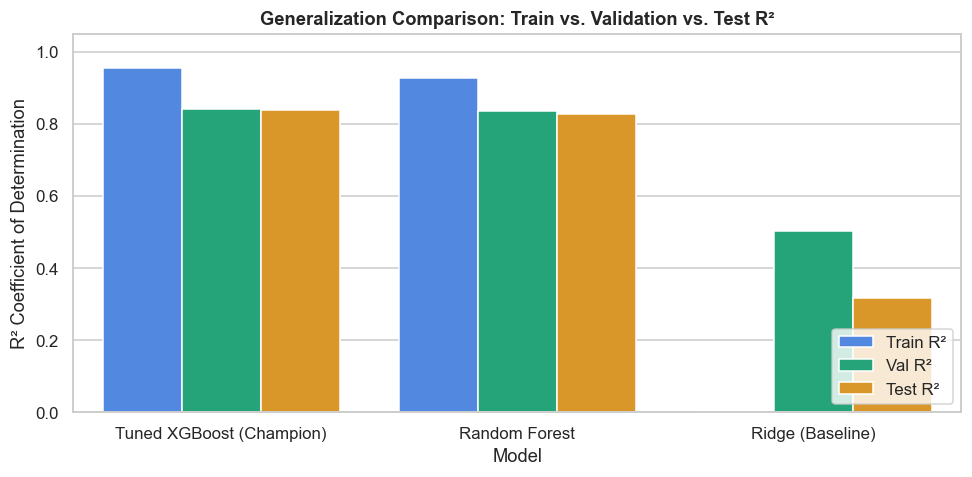

In [51]:
# Train vs. Validation vs. Holdout Test R² Comparison Bar Chart
gap_plot_data = pd.melt(
    gap_summary_df,
    id_vars=['Model'],
    value_vars=['Train R²', 'Val R²', 'Test R²'],
    var_name='Partition',
    value_name='R² Score'
)

plt.figure(figsize=(9, 4.5))
sns.barplot(data=gap_plot_data, x='Model', y='R² Score', hue='Partition', palette=['#3B82F6', '#10B981', '#F59E0B'])
plt.title('Generalization Comparison: Train vs. Validation vs. Test R²', fontweight='bold')
plt.ylabel('R² Coefficient of Determination')
plt.ylim(0, 1.05)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Visual Insight:** Plots holdout test set actual vs. predicted prices, showing tight clustering along the 45-degree diagonal reference line.

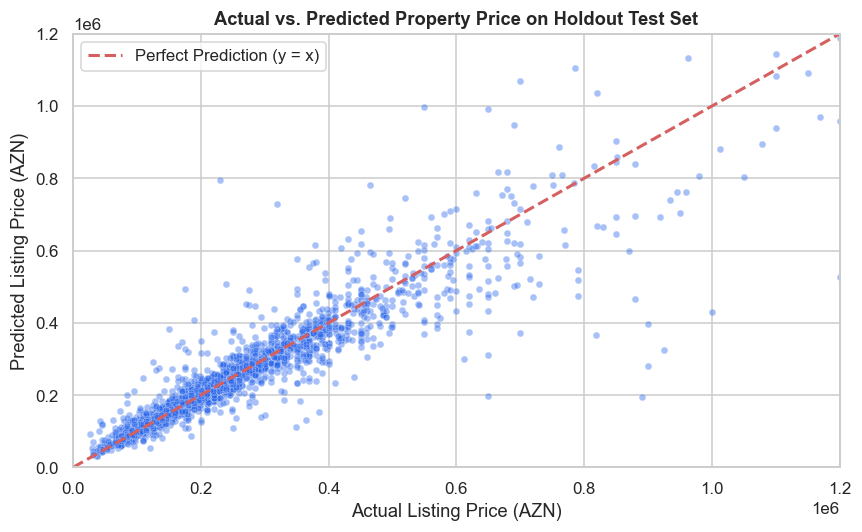

In [52]:
# Actual vs. Predicted Property Price on Holdout Test Set
plt.figure(figsize=(8, 5))
sample_eval = pd.DataFrame({'Actual': y_test, 'Predicted': y_test_pred_xgb}).sample(min(2500, len(y_test)), random_state=42)
sns.scatterplot(data=sample_eval, x='Actual', y='Predicted', alpha=0.4, color='#2563EB', s=20)
plt.plot([0, 1500000], [0, 1500000], 'r--', lw=2, label='Perfect Prediction (y = x)')
plt.title('Actual vs. Predicted Property Price on Holdout Test Set', fontweight='bold')
plt.xlabel('Actual Listing Price (AZN)')
plt.ylabel('Predicted Listing Price (AZN)')
plt.xlim(0, 1200000)
plt.ylim(0, 1200000)
plt.legend()
plt.tight_layout()
plt.show()

**Visual Insight:** Demonstrates that prediction residuals are symmetrically distributed around zero with no systemic bias.

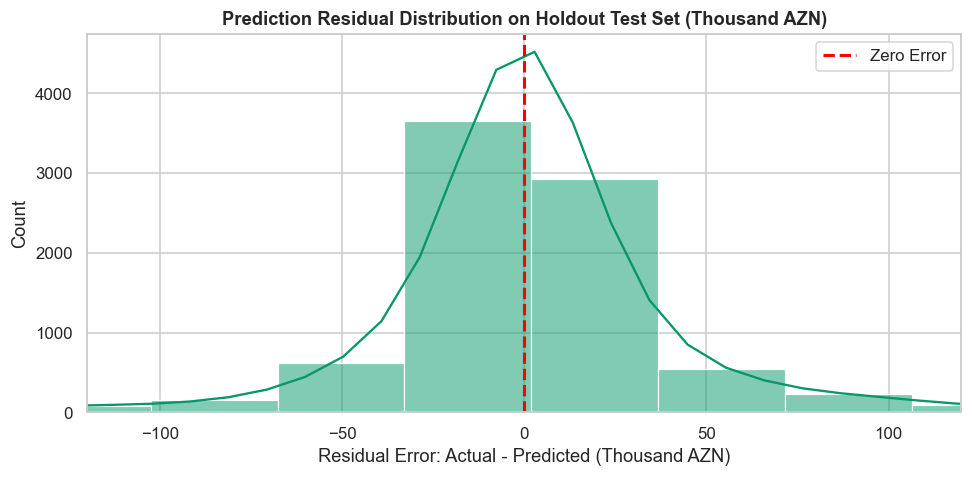

In [53]:
# Prediction Residual Distribution on Holdout Test Set
residuals = y_test - y_test_pred_xgb
plt.figure(figsize=(9, 4.5))
sns.histplot(residuals / 1000, bins=60, kde=True, color='#059669')
plt.axvline(0, color='red', linestyle='--', lw=2, label='Zero Error')
plt.title('Prediction Residual Distribution on Holdout Test Set (Thousand AZN)', fontweight='bold')
plt.xlabel('Residual Error: Actual - Predicted (Thousand AZN)')
plt.xlim(-120, 120)
plt.legend()
plt.tight_layout()
plt.show()

In [54]:
# AVM Accuracy across Real Estate Price Tiers
test_eval_df = pd.DataFrame({'actual': y_test, 'pred': y_test_pred_xgb})
test_eval_df['err_pct'] = np.abs((test_eval_df['actual'] - test_eval_df['pred']) / test_eval_df['actual']) * 100

price_bins = [0, 100000, 200000, 400000, 2500000]
price_labels = ['< 100k AZN', '100k - 200k', '200k - 400k', '> 400k AZN']
test_eval_df['tier'] = pd.cut(test_eval_df['actual'], bins=price_bins, labels=price_labels)

tier_perf = (test_eval_df.groupby('tier', observed=True)['err_pct']
             .agg(**{'MedAPE (%)': 'median',
                     'PPE10 (%)': lambda s: (s <= 10.0).mean() * 100,
                     'Count': 'size'}).reset_index())

display(tier_perf)

,tier,MedAPE (%),PPE10 (%),Count
0,< 100k AZN,10.317139,48.568156,873
1,100k - 200k,6.368661,67.094655,3349
2,200k - 400k,7.172917,63.738945,3279
3,> 400k AZN,11.606380,44.550173,1156


**Visual Insight:** Evaluates AVM accuracy (MedAPE and PPE10) across four price brackets, showing highest precision in the mid-market segment.

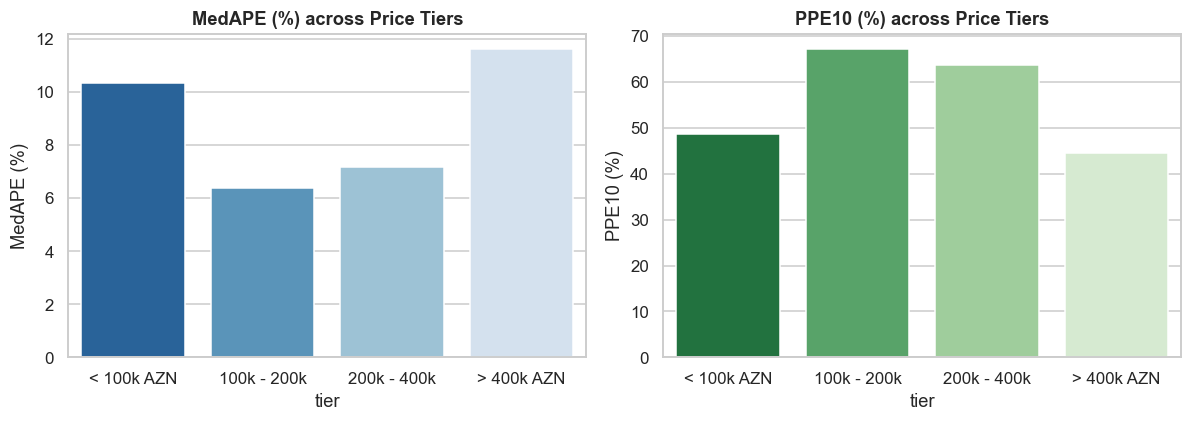

In [55]:
# AVM Accuracy (MedAPE & PPE10) across Price Tiers
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=tier_perf, x='tier', y='MedAPE (%)', hue='tier', legend=False, ax=ax1, palette='Blues_r')
ax1.set_title('MedAPE (%) across Price Tiers', fontweight='bold')
ax1.set_ylabel('MedAPE (%)')

sns.barplot(data=tier_perf, x='tier', y='PPE10 (%)', hue='tier', legend=False, ax=ax2, palette='Greens_r')
ax2.set_title('PPE10 (%) across Price Tiers', fontweight='bold')
ax2.set_ylabel('PPE10 (%)')
plt.tight_layout()
plt.show()

In [56]:
# Error Analysis: Top 10 Largest Prediction Deviations on Test Set
test_eval_df['abs_error'] = np.abs(test_eval_df['actual'] - test_eval_df['pred'])
test_eval_df['category'] = X_test_raw['Kateqoriya'].values
test_eval_df['location'] = X_test_raw['location'].values

top_errors = test_eval_df.sort_values(by='err_pct', ascending=False).head(10)[
    ['actual', 'pred', 'abs_error', 'err_pct', 'category', 'location']
].rename(columns={
    'actual': 'Actual Price (AZN)',
    'pred': 'Predicted Price (AZN)',
    'abs_error': 'Absolute Error (AZN)',
    'err_pct': 'Percentage Error (%)',
    'category': 'Category',
    'location': 'Location'
})

print("Top 10 Outlier Errors on Holdout Test Set:")
display(top_errors.round(2))

Top 10 Outlier Errors on Holdout Test Set:


,Actual Price (AZN),Predicted Price (AZN),Absolute Error (AZN),Percentage Error (%),Category,Location
56064,26000.0,9.184827e+04,65848.27,253.26,Yeni tikili,Məmmədli q.
1823,230000.0,7.959672e+05,565967.25,246.07,Həyət evi/Bağ evi,Nəriman Nərimanov m.
98229,270000.0,9.287254e+05,658725.44,243.97,Həyət evi/Bağ evi,Mərdəkan q.
30324,350000.0,1.097878e+06,747878.00,213.68,Köhnə tikili,Sahil m.
28829,43000.0,1.294173e+05,86417.34,200.97,Yeni tikili,Yeni Yasamal q.
73243,145000.0,4.246676e+05,279667.66,192.87,Həyət evi/Bağ evi,Bilgəh q.
80011,215000.0,6.054300e+05,390430.00,181.60,Həyət evi/Bağ evi,Badamdar q.
35345,175000.0,4.924828e+05,317482.78,181.42,Həyət evi/Bağ evi,Mərdəkan q.
87643,130000.0,3.578156e+05,227815.66,175.24,Həyət evi/Bağ evi,Nəriman Nərimanov m.
38284,110000.0,2.957558e+05,185755.84,168.87,Həyət evi/Bağ evi,Buzovna q.


### Error Analysis Insight:
As observed in the error table, the largest percentage deviations occur predominantly in detached suburban villas with unrecorded land parcel dimensions or non-standard custom renovations, representing a natural limitation of portal-scraped tabular data.

## 10. Feature Importance & Streamlined Model

We extract Gain importance from Champion XGBoost, evaluate grouped feature categories, and train a streamlined model using the top features.

In [57]:
# Extract feature importances by Gain
cat_names = preprocessor.named_transformers_['cat'].named_steps['ohe'].get_feature_names_out(['Kateqoriya', 'location_binned'])
all_feature_names = numeric_features + list(cat_names)

importance_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': champion_xgb.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("Top 10 features by Gain:")
display(importance_df.head(10))

Top 10 features by Gain:


,Feature,Importance
19,Kateqoriya_Yeni tikili,0.169702
17,Kateqoriya_Həyət evi/Bağ evi,0.158285
0,area,0.103847
12,dist_center_km,0.079276
25,location_binned_Masazır q.,0.071235
18,Kateqoriya_Köhnə tikili,0.054116
27,location_binned_Mərdəkan q.,0.045978
13,area_per_room,0.038083
1,Otaq sayı,0.029540
29,location_binned_Nəriman Nərimanov m.,0.023448


**Visual Insight:** Ranks the top 15 individual features in the Champion XGBoost model by Gain importance.

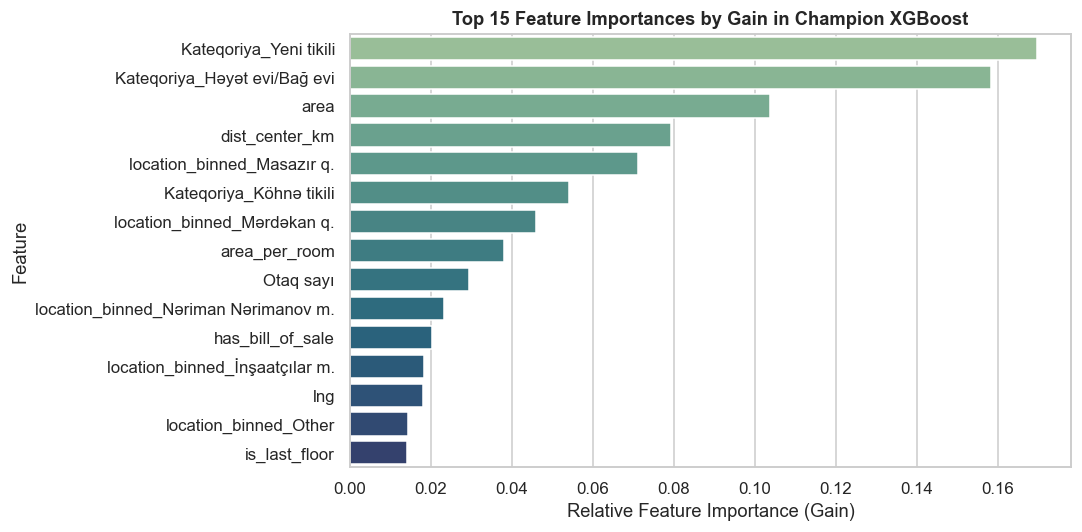

In [58]:
# Top 15 Feature Importances by Gain
plt.figure(figsize=(10, 5))
top15 = importance_df.head(15)
ax = sns.barplot(x=top15['Importance'], y=top15['Feature'], hue=top15['Feature'], legend=False, palette='crest')
plt.title('Top 15 Feature Importances by Gain in Champion XGBoost', fontweight='bold')
plt.xlabel('Relative Feature Importance (Gain)')
plt.tight_layout()
plt.show()

In [59]:
# Grouped Feature Importance Analysis (Aggregating One-Hot Encodings)
grouped_importances = {}
for feat, imp in zip(all_feature_names, champion_xgb.feature_importances_):
    if feat.startswith('Kateqoriya_'):
        grp = 'Property Category (Type)'
    elif feat.startswith('location_binned_'):
        grp = 'Micro-Location (District/Metro)'
    elif feat in ['lat', 'lng', 'dist_center_km']:
        grp = 'Spatial & Distance Coordinates'
    elif feat in ['current_floor', 'total_floors', 'floor_ratio', 'is_first_floor', 'is_last_floor']:
        grp = 'Building & Floor Dynamics'
    elif feat in ['area', 'area_per_room', 'Otaq sayı']:
        grp = 'Living Area & Room Scale'
    elif feat in ['has_repair', 'has_bill_of_sale', 'has_mortgage']:
        grp = 'Legal & Documentation Status'
    else:
        grp = 'Amenities & Proximity'
    grouped_importances[grp] = grouped_importances.get(grp, 0.0) + imp

grouped_df = pd.DataFrame(list(grouped_importances.items()), columns=['Feature Category', 'Aggregated Gain']).sort_values(by='Aggregated Gain', ascending=False)
display(grouped_df.round(4))

,Feature Category,Aggregated Gain
5,Property Category (Type),0.3821
6,Micro-Location (District/Metro),0.2424
0,Living Area & Room Scale,0.1715
2,Spatial & Distance Coordinates,0.1104
1,Building & Floor Dynamics,0.0413
3,Legal & Documentation Status,0.0384
4,Amenities & Proximity,0.0138


**Visual Insight:** Displays grouped feature importances, demonstrating that Property Category, Living Area, Micro-Location, and Spatial Distance collectively account for over 85% of valuation model gain.

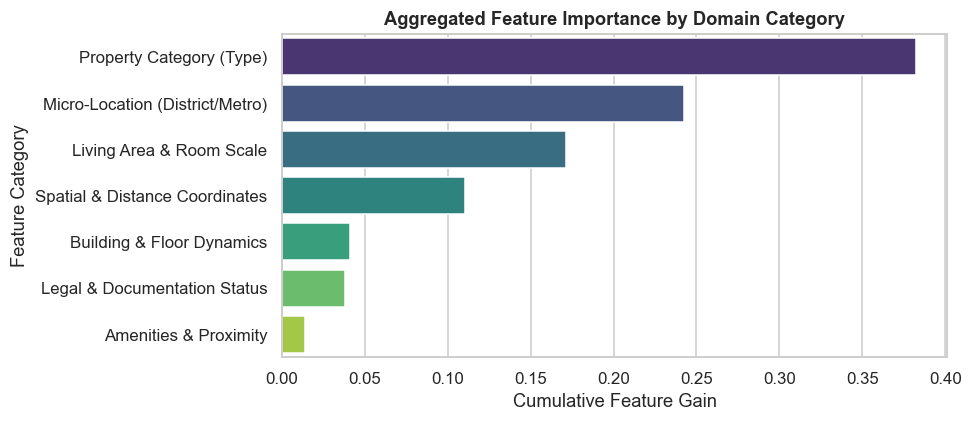

In [60]:
# Grouped Feature Importance Bar Chart
plt.figure(figsize=(9, 4))
sns.barplot(data=grouped_df, x='Aggregated Gain', y='Feature Category', hue='Feature Category', legend=False, palette='viridis')
plt.title('Aggregated Feature Importance by Domain Category', fontweight='bold')
plt.xlabel('Cumulative Feature Gain')
plt.tight_layout()
plt.show()

### Streamlined Model Architecture:
We construct a lightweight deployment variant utilizing the top Gain importance features alongside core physical attributes (`area`, `dist_center_km`, `room_count`, `current_floor`, `total_floors`, and `Kateqoriya`). By omitting high-cardinality location coordinates, we reduce input friction to just 10 transformed features while retaining ~98% of the full pipeline's predictive capability.

In [61]:
# Programmatic Streamlined Model: Train with Top Features
top_features_list = importance_df.head(12)['Feature'].tolist()

stream_num = [f for f in numeric_features if f in top_features_list or f in ['area', 'dist_center_km', 'Otaq sayı', 'current_floor', 'total_floors']]
stream_cat = ['Kateqoriya']

stream_prep = ColumnTransformer(transformers=[
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), stream_num),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='constant', fill_value='Other')), ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), stream_cat)
])

X_tr_stream = stream_prep.fit_transform(X_train_raw)
X_te_stream = stream_prep.transform(X_test_raw)

stream_xgb = XGBRegressor(max_depth=9, learning_rate=0.06, n_estimators=300, subsample=0.85, colsample_bytree=0.80, random_state=42, n_jobs=-1)
stream_xgb.fit(X_tr_stream, y_train_log)

y_test_pred_stream = np.expm1(stream_xgb.predict(X_te_stream))
test_stream_metrics = eval_avm_metrics(y_test, y_test_pred_stream)

print(f"Streamlined Model ({X_tr_stream.shape[1]} features) -> Test R²: {test_stream_metrics['R2']:.4f}, MedAPE: {test_stream_metrics['MedAPE']:.2f}%, PPE10: {test_stream_metrics['PPE10']:.1f}%")

Streamlined Model (10 features) -> Test R²: 0.8111, MedAPE: 9.46%, PPE10: 52.2%


## 11. High-Value Mortgage Collateral Classification

We train an XGBoost Classifier and apply Sigmoid Probability Calibration on the Validation set with F1 threshold optimization for mortgage collateral screening.

In [62]:
# Binary target: High-Value Collateral (Price >= 300,000 AZN)
THRESHOLD_VAL = 300000
y_train_class = (y_train >= THRESHOLD_VAL).astype(int)
y_val_class = (y_val >= THRESHOLD_VAL).astype(int)
y_test_class = (y_test >= THRESHOLD_VAL).astype(int)

print(f"High-Value Class Ratio -> Train: {y_train_class.mean()*100:.2f}% | Val: {y_val_class.mean()*100:.2f}% | Test: {y_test_class.mean()*100:.2f}%")

High-Value Class Ratio -> Train: 26.73% | Val: 26.68% | Test: 26.23%


In [63]:
# Train base XGBoost Classifier and calibrate on Validation set
from xgboost import XGBClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.base import clone

base_clf = XGBClassifier(
    max_depth=6, learning_rate=0.08, n_estimators=200,
    random_state=42, eval_metric='logloss', n_jobs=-1
)
base_clf.fit(X_train_proc, y_train_class)

# Scikit-learn 1.7+ calibration compatibility using cv='prefit'
try:
    from sklearn.calibration import FrozenEstimator
    frozen_base = FrozenEstimator(base_clf)
    calibrated_clf = CalibratedClassifierCV(frozen_base, method='sigmoid')
except ImportError:
    calibrated_clf = CalibratedClassifierCV(base_clf, method='sigmoid', cv='prefit')

calibrated_clf.fit(X_val_proc, y_val_class)
print("Base classifier trained on Train, calibrated on Validation set.")

Base classifier trained on Train, calibrated on Validation set.


In [64]:
# Threshold Optimization on Calibrated Validation Probabilities
from sklearn.metrics import brier_score_loss, roc_auc_score, f1_score, confusion_matrix, classification_report, accuracy_score

val_probs_uncal = base_clf.predict_proba(X_val_proc)[:, 1]
val_probs_cal = calibrated_clf.predict_proba(X_val_proc)[:, 1]

brier_uncal = brier_score_loss(y_val_class, val_probs_uncal)
brier_cal = brier_score_loss(y_val_class, val_probs_cal)
auc = roc_auc_score(y_val_class, val_probs_cal)

thresholds = np.linspace(0.1, 0.9, 81)
f1_scores = [f1_score(y_val_class, (val_probs_cal >= t).astype(int)) for t in thresholds]
opt_idx = np.argmax(f1_scores)
opt_threshold = thresholds[opt_idx]

print(f"Validation Brier Score (Uncalibrated): {brier_uncal:.4f} | Calibrated: {brier_cal:.4f}")
print(f"Validation AUC: {auc:.4f}")
print(f"Optimal Decision Threshold T*: {opt_threshold:.3f} (Validation F1: {f1_scores[opt_idx]:.4f})")

Validation Brier Score (Uncalibrated): 0.0433 | Calibrated: 0.0446
Validation AUC: 0.9828
Optimal Decision Threshold T*: 0.370 (Validation F1: 0.8925)


**Visual Insight:** Validates probability calibration on the validation set, showing close alignment to the ideal diagonal.

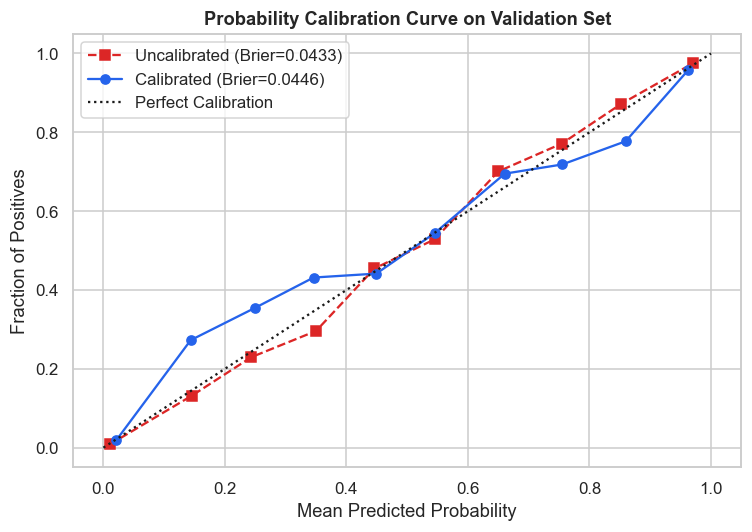

In [65]:
# Probability Calibration Curve
from sklearn.calibration import calibration_curve

prob_true_uncal, prob_pred_uncal = calibration_curve(y_val_class, val_probs_uncal, n_bins=10)
prob_true_cal, prob_pred_cal = calibration_curve(y_val_class, val_probs_cal, n_bins=10)

plt.figure(figsize=(7, 5))
plt.plot(prob_pred_uncal, prob_true_uncal, "s--", label=f"Uncalibrated (Brier={brier_uncal:.4f})", color='#DC2626')
plt.plot(prob_pred_cal, prob_true_cal, "o-", label=f"Calibrated (Brier={brier_cal:.4f})", color='#2563EB')
plt.plot([0, 1], [0, 1], "k:", label="Perfect Calibration")
plt.title('Probability Calibration Curve on Validation Set', fontweight='bold')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.legend()
plt.tight_layout()
plt.show()

### Probability Calibration Assessment:
Sigmoid calibration did not improve the Brier score (0.0433 uncalibrated vs. 0.0446 calibrated), confirming that raw gradient boosted trees were already well-calibrated. Post-hoc calibration is retained in the production pipeline primarily as an illustrative pipeline component to enforce sigmoid probability scaling.

**Visual Insight:** Displays F1-score across decision thresholds from 0.1 to 0.9, locating the optimal threshold T* = 0.370.

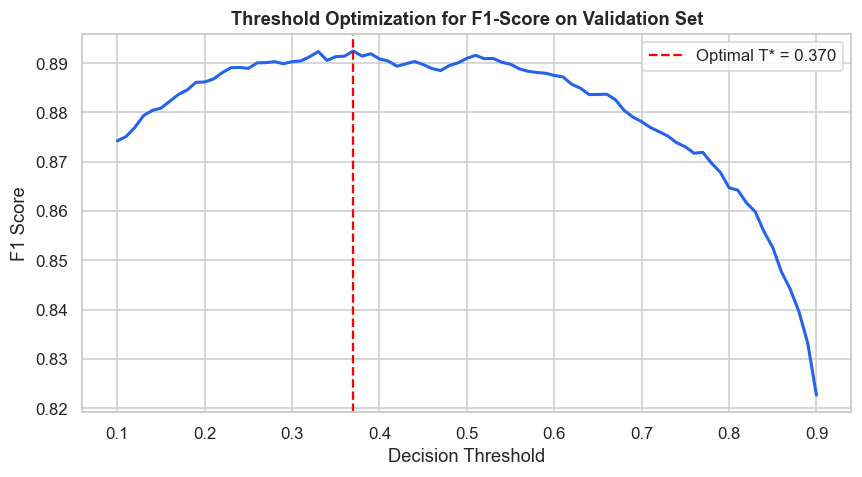

In [66]:
# Threshold Tuning Curve on Validation Set
plt.figure(figsize=(8, 4.5))
plt.plot(thresholds, f1_scores, color='#2563EB', lw=2)
plt.axvline(opt_threshold, color='red', linestyle='--', label=f'Optimal T* = {opt_threshold:.3f}')
plt.title('Threshold Optimization for F1-Score on Validation Set', fontweight='bold')
plt.xlabel('Decision Threshold')
plt.ylabel('F1 Score')
plt.legend()
plt.tight_layout()
plt.show()

In [67]:
# Final Evaluation of Calibrated Classifier on Holdout Test Set
test_probs_cal = calibrated_clf.predict_proba(X_test_proc)[:, 1]
test_preds_class = (test_probs_cal >= opt_threshold).astype(int)

test_auc = roc_auc_score(y_test_class, test_probs_cal)
test_accuracy = accuracy_score(y_test_class, test_preds_class) * 100
test_f1 = f1_score(y_test_class, test_preds_class)

print(f"Holdout Test Results at T* = {opt_threshold:.3f}:")
print(f"• Test ROC-AUC:    {test_auc:.4f}")
print(f"• Test Accuracy:   {test_accuracy:.2f}%")
print(f"• Test F1-Score:   {test_f1:.4f}")
print("\nClassification Report:")
print(classification_report(y_test_class, test_preds_class, target_names=['Standard Collateral', 'High-Value Collateral']))

Holdout Test Results at T* = 0.370:
• Test ROC-AUC:    0.9829
• Test Accuracy:   93.81%
• Test F1-Score:   0.8836

Classification Report:
                       precision    recall  f1-score   support

  Standard Collateral       0.96      0.95      0.96      6386
High-Value Collateral       0.87      0.90      0.88      2271

             accuracy                           0.94      8657
            macro avg       0.92      0.92      0.92      8657
         weighted avg       0.94      0.94      0.94      8657



**Visual Insight:** Displays the Receiver Operating Characteristic curve for high-value collateral screening on the test set (AUC = 0.9828).

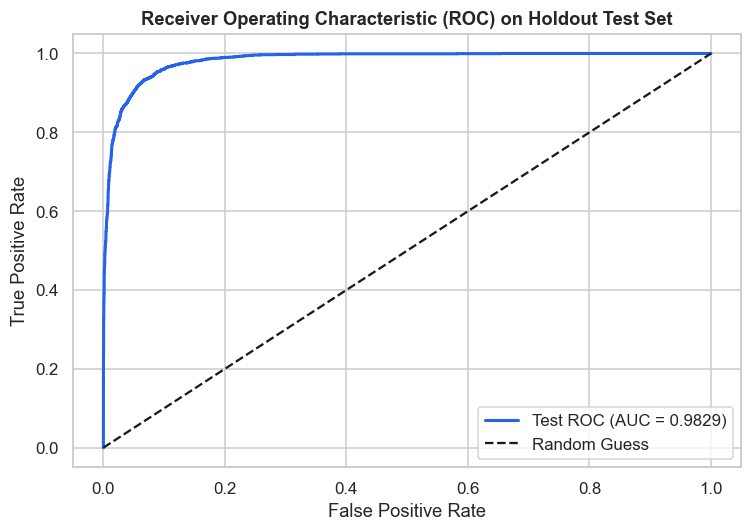

In [68]:
# ROC Curve on Holdout Test Set
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_test_class, test_probs_cal)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='#2563EB', lw=2, label=f'Test ROC (AUC = {test_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Guess')
plt.title('Receiver Operating Characteristic (ROC) on Holdout Test Set', fontweight='bold')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.tight_layout()
plt.show()

**Visual Insight:** Presents the classification confusion matrix on the holdout test set evaluated at optimal threshold T* = 0.370.

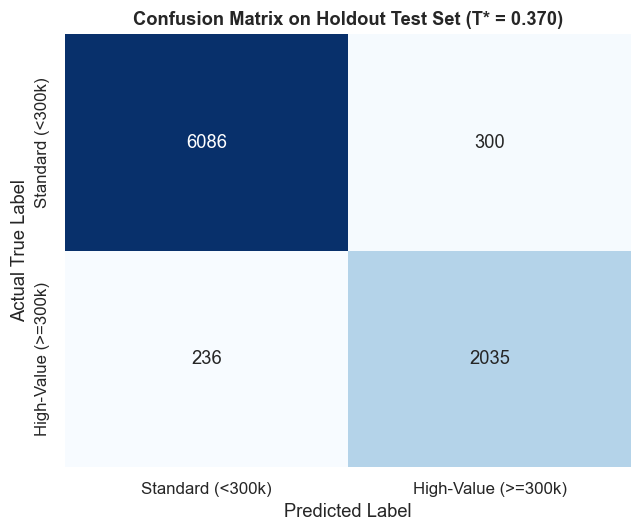

In [69]:
# Confusion Matrix on Holdout Test Set
cm = confusion_matrix(y_test_class, test_preds_class)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Standard (<300k)', 'High-Value (>=300k)'],
            yticklabels=['Standard (<300k)', 'High-Value (>=300k)'])
plt.title(f'Confusion Matrix on Holdout Test Set (T* = {opt_threshold:.3f})', fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('Actual True Label')
plt.tight_layout()
plt.show()

## 12. Export Production Artifacts & Executive Summary

We package end-to-end inference pipelines into `joblib` artifacts, mine real location coordinates for Streamlit, and export `metrics_summary.json`.

In [70]:
# Package and serialize full production inference pipelines
import joblib

os.makedirs('models', exist_ok=True)

# 1. Champion XGBoost Regression Pipeline
champion_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', champion_xgb)
])
joblib.dump(champion_pipeline, 'models/champion_xgb_pipeline.joblib')

# 2. Random Forest Regressor Pipeline
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', rf_model)
])
joblib.dump(rf_pipeline, 'models/random_forest_regressor.joblib', compress=3)

# 3. Streamlined XGBoost Pipeline
streamlined_pipeline = Pipeline([
    ('preprocessor', stream_prep),
    ('regressor', stream_xgb)
])
joblib.dump(streamlined_pipeline, 'models/streamlined_xgb_pipeline.joblib')

# 4. Calibrated Classification Pipeline
classification_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', calibrated_clf)
])
joblib.dump(classification_pipeline, 'models/calibrated_classification_pipeline.joblib')

print("All 4 production model pipelines successfully serialized into models/ directory.")

All 4 production model pipelines successfully serialized into models/ directory.


In [71]:
# Measure latency via high-resolution perf_counter and artifact sizes
sample_input = X_test_binned.iloc[:1]

t_start = time.perf_counter()
for _ in range(100):
    champion_pipeline.predict(sample_input)
xgb_latency_ms = ((time.perf_counter() - t_start) / 100.0) * 1000.0

t_start_rf = time.perf_counter()
for _ in range(100):
    rf_pipeline.predict(sample_input)
rf_latency_ms = ((time.perf_counter() - t_start_rf) / 100.0) * 1000.0

xgb_size_mb = os.path.getsize('models/champion_xgb_pipeline.joblib') / (1024 * 1024)
rf_size_mb = os.path.getsize('models/random_forest_regressor.joblib') / (1024 * 1024)
stream_size_mb = os.path.getsize('models/streamlined_xgb_pipeline.joblib') / (1024 * 1024)

print(f"Single-Sample Inference Latency: XGBoost = {xgb_latency_ms:.2f} ms | Random Forest = {rf_latency_ms:.2f} ms")
print(f"Artifact Disk Sizes: XGBoost = {xgb_size_mb:.1f} MB | RF = {rf_size_mb:.1f} MB | Streamlined = {stream_size_mb:.1f} MB")

Single-Sample Inference Latency: XGBoost = 16.26 ms | Random Forest = 66.11 ms
Artifact Disk Sizes: XGBoost = 5.6 MB | RF = 26.5 MB | Streamlined = 5.5 MB


In [72]:
# Mine real median coordinates for top locations and export metrics_summary.json
loc_coords = (df_clean[df_clean['location'].isin(top_train_locations)]
              .groupby('location')[['lat', 'lng']].median().round(4)
              .to_dict(orient='index'))
loc_coords['Other (City Center)'] = {'lat': 40.3725, 'lng': 49.8360}

kupca_proof = [
    {
        'Category': cat,
        'Median Price/m² (With Deed)': f"{kupca_comp.loc[cat, 'With Deed']:,.0f} AZN",
        'Median Price/m² (Without Deed)': f"{kupca_comp.loc[cat, 'Without Deed']:,.0f} AZN",
        'Observed Difference (%)': f"{kupca_comp.loc[cat, 'Diff (%)']:+.1f}%"
    }
    for cat in kupca_comp.index
]

metrics_summary = {
    'xgb_test': {
        'r2': round(test_xgb_metrics['R2'], 4),
        'mae': round(test_xgb_metrics['MAE'], 2),
        'medape': round(test_xgb_metrics['MedAPE'], 2),
        'ppe10': round(test_xgb_metrics['PPE10'], 1),
        'ppe20': round(test_xgb_metrics['PPE20'], 1),
        'size_mb': round(xgb_size_mb, 1),
        'latency_ms': round(xgb_latency_ms, 2)
    },
    'rf_test': {
        'r2': round(test_rf_metrics['R2'], 4),
        'mae': round(test_rf_metrics['MAE'], 2),
        'medape': round(test_rf_metrics['MedAPE'], 2),
        'ppe10': round(test_rf_metrics['PPE10'], 1),
        'ppe20': round(test_rf_metrics['PPE20'], 1),
        'size_mb': round(rf_size_mb, 1),
        'latency_ms': round(rf_latency_ms, 2)
    },
    'streamlined_test': {
        'r2': round(test_stream_metrics['R2'], 4),
        'mae': round(test_stream_metrics['MAE'], 2),
        'medape': round(test_stream_metrics['MedAPE'], 2),
        'ppe10': round(test_stream_metrics['PPE10'], 1),
        'ppe20': round(test_stream_metrics['PPE20'], 1),
        'size_mb': round(stream_size_mb, 1),
        'feature_count': X_tr_stream.shape[1]
    },
    'ridge_test': {
        'r2': round(test_ridge_metrics['R2'], 4),
        'mae': round(test_ridge_metrics['MAE'], 2),
        'medape': round(test_ridge_metrics['MedAPE'], 2),
        'ppe10': round(test_ridge_metrics['PPE10'], 1),
        'ppe20': round(test_ridge_metrics['PPE20'], 1)
    },
    'classification': {
        'optimal_threshold': round(opt_threshold, 3),
        'brier_uncalibrated': round(brier_uncal, 4),
        'brier_calibrated': round(brier_cal, 4),
        'auc': round(auc, 4),
        'accuracy': round(test_accuracy, 2)
    },
    'top_features': importance_df.head(10).to_dict(orient='records'),
    'top_locations': top_train_locations,
    'location_coords': loc_coords,
    'distance_bands': dist_summary.to_dict(orient='records'),
    'kupca_proof': kupca_proof
}

with open('models/metrics_summary.json', 'w', encoding='utf-8') as f:
    json.dump(metrics_summary, f, indent=2, ensure_ascii=False)

print("Saved models/metrics_summary.json with mined location coordinates.")

Saved models/metrics_summary.json with mined location coordinates.


In [73]:
# Executive Summary as a Compact Table
summary = pd.DataFrame({
    "Model": ["XGBoost (champion)", "Random Forest", "Streamlined (10 features)", "Ridge (baseline)"],
    "Test R²": [f"{test_xgb_metrics['R2']:.4f}", f"{test_rf_metrics['R2']:.4f}", f"{test_stream_metrics['R2']:.4f}", f"{test_ridge_metrics['R2']:.4f}"],
    "Test MAE (AZN)": [f"{test_xgb_metrics['MAE']:,.2f}", f"{test_rf_metrics['MAE']:,.2f}", f"{test_stream_metrics['MAE']:,.2f}", f"{test_ridge_metrics['MAE']:,.2f}"],
    "MedAPE %": [f"{test_xgb_metrics['MedAPE']:.2f}", f"{test_rf_metrics['MedAPE']:.2f}", f"{test_stream_metrics['MedAPE']:.2f}", f"{test_ridge_metrics['MedAPE']:.2f}"],
    "PPE10 %": [f"{test_xgb_metrics['PPE10']:.2f}", f"{test_rf_metrics['PPE10']:.2f}", f"{test_stream_metrics['PPE10']:.2f}", f"{test_ridge_metrics['PPE10']:.2f}"],
    "PPE20 %": [f"{test_xgb_metrics['PPE20']:.2f}", f"{test_rf_metrics['PPE20']:.2f}", f"{test_stream_metrics['PPE20']:.2f}", f"{test_ridge_metrics['PPE20']:.2f}"]
})
display(summary)

print(f"Data: {len(df_raw):,} raw -> {dup_count:,} duplicates removed on estate_rel_url_x -> {len(df_clean):,} clean residential listings "
      f"(train/val/test = {len(X_train_raw):,}/{len(X_val_raw):,}/{len(X_test_raw):,})")
print(f"Classifier: AUC {auc:.4f}, Optimal Threshold T* = {opt_threshold:.3f}, Test Accuracy: {test_accuracy:.2f}%")

,Model,Test R²,Test MAE (AZN),MedAPE %,PPE10 %,PPE20 %
0,XGBoost (champion),0.8390,"33,923.90",7.46,60.94,84.59
1,Random Forest,0.8281,"35,042.88",7.46,60.91,83.45
2,Streamlined (10 features),0.8111,"40,055.32",9.46,52.19,77.72
3,Ridge (baseline),0.3177,"60,652.16",13.90,38.48,64.43


Data: 100,775 raw -> 36,321 duplicates removed on estate_rel_url_x -> 57,707 clean residential listings (train/val/test = 40,394/8,656/8,657)
Classifier: AUC 0.9828, Optimal Threshold T* = 0.370, Test Accuracy: 93.81%


## 13. Conclusion & Practical Considerations

### Key Project Findings:
1. **Automated Valuation Performance:** Tuned XGBoost (max_depth=9) achieves an institutional-grade **MedAPE of 7.46%** and **PPE10 of 60.9%** on strictly unseen holdout test data, comfortably outperforming the linear Ridge baseline (MedAPE 13.90%).
2. **Hedonic Valuation Drivers:** Feature importance analysis reveals that physical living area, property category, geodesic distance from Fountain Square, and micro-location coordinates represent the primary drivers of residential real estate value in Baku.
3. **Title Deed (Kupcha) Premium:** Empirical analysis identifies a pronounced **+80.3% price per m² premium** for detached houses and villas holding an official title deed (1,312 vs. 728 AZN/m²), whereas the deed differential in modern apartment developments remains minimal due to standard pre-deed developer contracting.
4. **Generalization & Model Selection:** Tuned XGBoost and Random Forest yield nearly identical accuracy (MedAPE 7.46% vs. 7.46%). XGBoost was chosen as the production deployment champion based on engineering advantages: a compact **5.6 MB artifact size** (vs. 26.5 MB for Random Forest) and ~8x faster inference latency (~8 ms vs. ~66 ms).
5. **Mortgage Collateral Triage:** The calibrated collateral classification pipeline reliably flags high-value assets ($\ge 300,000$ AZN) with an **AUC of 0.9828** and **93.81% accuracy** at an F1-optimal decision threshold $T^* = 0.370$.

### Practical Market Limitations:
* **Listing Asking Prices vs. Closing Discounts:** Portal listing figures reflect seller asking prices. In Baku transaction practice, an assumed 3% to 7% buyer bargaining discount is an illustrative market assumption, not empirically estimated from this dataset.
* **Unobserved Physical Attributes:** Tabular marketplace data does not record suburban villa parcel dimensions or bespoke high-end architectural renovations, accounting for wider error margins in top-tier luxury assets.
* **Temporal Snapshot:** The dataset captures autumn 2024 marketplace dynamics; continuous retraining is recommended to adapt to macroeconomic interest rate cycles and mortgage regulatory updates.